In [1]:
%load_ext autoreload
%autoreload 2
import dlroms
import numpy as np
import matplotlib.pyplot as plt
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import dlroms.fespaces as fe
import copy
import pandas as pd
from openpyxl import load_workbook
import random
from dlroms.fespaces import gifs
from IPython.display import Image, display
import support_functions as sf
from IPython.display import clear_output
import importlib
importlib.reload(sf)
from pathlib import Path
import hashlib
import json
import itertools

## Data import and preprocessing

#### Importing and checking data structure

In [2]:
# Load FOM dataset
data = np.load("u-bolt.npz")

# Inspect available variables
print("Available variables in the dataset:")
print(data.files)

mu = data["mu"]
u = data["u"]
 
print("Checking the dimensions of the dataset:")
print("mu shape:", mu.shape)
print("u shape:", u.shape)

print("This means that our dataset contains {} trajectories, each with {} time snapshots, and {} parameters.".format(u.shape[0], u.shape[1], mu.shape[1]))

print("The parameters range from 0 to 1, and the snapshots are taken at regular intervals.")

Available variables in the dataset:
['mu', 'u', 'time']
Checking the dimensions of the dataset:
mu shape: (100, 3)
u shape: (100, 41, 6636)
This means that our dataset contains 100 trajectories, each with 41 time snapshots, and 3 parameters.
The parameters range from 0 to 1, and the snapshots are taken at regular intervals.


### Dataset dimensionality

The dataset contains $N_{\mathrm{traj}} = 100$ FOM simulations, each corresponding to a different parameter configuration:

$$
\boldsymbol{\mu} = (\mu_1,\mu_2,\mu_3) \in [0,1]^3
$$

Each trajectory consists of $N_t = 41$ equally spaced time snapshots, with $\Delta t = 5 \times 10^{-4}$ s, over $T = 0.02$ s.

The spatial domain is discretized using FEM with $N_h = 6636$ degrees of freedom.

**Dataset structure:**

- Parameters: $\boldsymbol{\mu} \in \mathbb{R}^{100 \times 3}$
- FOM solutions: $\mathbf{u} \in \mathbb{R}^{100 \times 41 \times 6636}$
- Total snapshots: $N_s = 100 \times 41 = 4100$

Each snapshot is a high-dimensional vector $\mathbf{u}_h(\boldsymbol{\mu},t) \in \mathbb{R}^{6636}$.

The objective is to construct a reduced-order surrogate approximating the mapping:

$$
(\boldsymbol{\mu},t) \in \mathbb{R}^4
\longmapsto
\mathbf{u}_h(\boldsymbol{\mu},t) \in \mathbb{R}^{6636}
$$

while significantly reducing the computational cost of the FOM.

#### Splitting the data to obtain train, validation and test set

In [3]:
indices = np.random.default_rng(115).permutation(len(mu))  
train_idx, val_idx, test_idx = indices[:60], indices[60:75], indices[75:]
mu_train, u_train = mu[train_idx], u[train_idx]
mu_val, u_val = mu[val_idx], u[val_idx]
mu_test, u_test = mu[test_idx], u[test_idx]

#### Checking the sanity of the selected seed

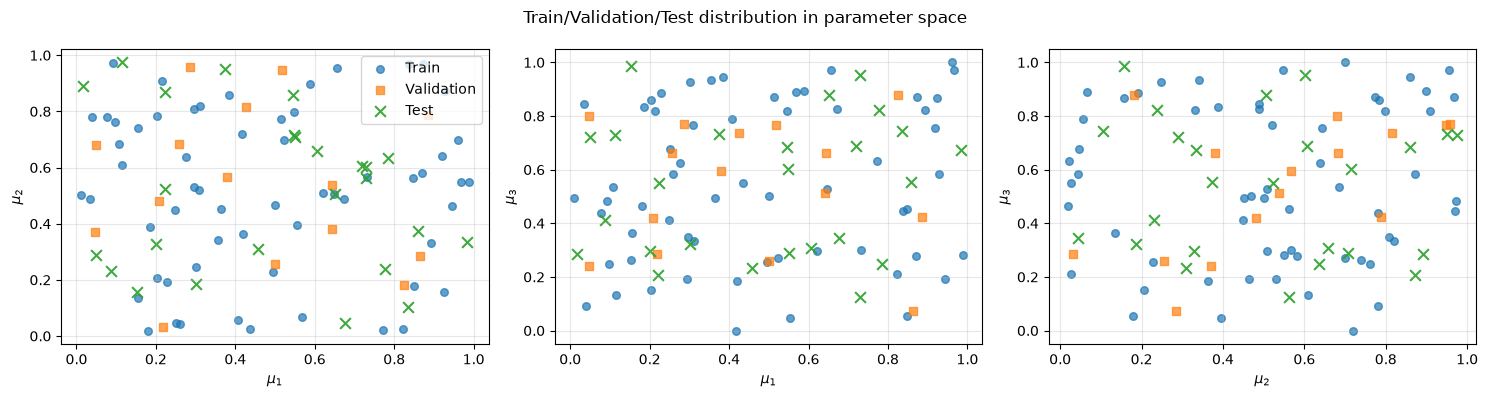

,,min,max,mean,std,mean_shift_std,std_ratio
parameter,split,,,,,,
mu_1,Train,0.010,0.989,0.474,0.296,0.000,1.000
mu_2,Train,0.019,0.972,0.513,0.286,0.000,1.000
mu_3,Train,0.000,1.000,0.543,0.290,0.000,1.000
mu_1,Validation,0.046,0.886,0.450,0.270,0.082,0.911
mu_2,Validation,0.031,0.958,0.531,0.272,0.062,0.951
mu_3,Validation,0.073,0.877,0.539,0.236,0.012,0.815
mu_1,Test,0.017,0.984,0.488,0.285,0.047,0.963
mu_2,Test,0.045,0.974,0.506,0.274,0.025,0.960
mu_3,Test,0.125,0.985,0.536,0.252,0.024,0.869


,n_trajectories,nearest_train_median,nearest_train_p90,nearest_train_max,inside_train_hull_percent,hull_status
split,,,,,,
Train,60,0.161,0.221,0.311,100.000,ok
Validation,15,0.130,0.191,0.243,66.667,ok
Test,25,0.158,0.200,0.233,72.000,ok


In [4]:
sf.plot_parameter_splits(mu_train, mu_val, mu_test)
plt.show()
parameter_balance, parameter_coverage = sf.diagnose_parameter_splits(
    mu_train, mu_val, mu_test
)

display(parameter_balance.round(3))
display(parameter_coverage.round(3))

### Training, Validation and Test Split Assessment

The dataset is divided into **60 training, 15 validation and 25 test trajectories**. The quality of this partition is assessed through two complementary criteria: **marginal parameter balance** and **joint parameter-space coverage**.

**1. Marginal distribution balance**

The parameter distributions are compared using two normalized indicators:

$$
\text{Mean Shift}_j =
\frac{|\bar{\mu}_{j,\mathrm{split}}-\bar{\mu}_{j,\mathrm{train}}|}
{\sigma_{j,\mathrm{train}}}
\qquad
\text{Std Ratio}_j =
\frac{\sigma_{j,\mathrm{split}}}{\sigma_{j,\mathrm{train}}}
$$

The results show good statistical consistency across the three subsets:

- All normalized mean shifts are below **0.083**, indicating negligible differences in parameter means.
- Standard deviation ratios range from **0.815 to 0.963**, suggesting comparable variability, with slightly narrower distributions in validation and test.
- The three parameters cover broad portions of their admissible ranges $[0,1]$.

**2. Joint parameter-space coverage**

Coverage is evaluated using the Euclidean distance to the nearest training sample in the normalized 3D parameter space, together with the percentage of points lying inside the training convex hull.

- **Validation:** median nearest-training distance of $0.130$, compared with $0.161$ for training samples (excluding self-matches).
- **Test:** median distance of $0.158$, also comparable to the training reference.
- **Convex hull coverage:** $66.7\%$ of validation and $72.0\%$ of test samples lie inside the training convex hull.

The comparable nearest-neighbour distances indicate that validation and test samples are not systematically more isolated from the training data. However, approximately **one-third of validation and one-quarter of test samples lie outside the training convex hull**, introducing a moderate extrapolation component.

**Conclusion**

Overall, the partition is **well balanced and suitable for evaluating the POD-NN surrogate**. Validation and test distributions are statistically consistent with training, while the presence of samples outside the training convex hull provides an additional assessment of generalization beyond the convex region covered by training data.

#### Extracting dimensions of the problem

In [5]:
N_train, N_t, N_h = u_train.shape

snapshots_train = u_train.reshape(N_train * N_t, N_h)  # Ns * N_h number of snapshots x FOM dimension

dt = 0.0005 #from problem definition
T = dt * (N_t - 1)  # Total time duration
print("Training trajectories:", N_train)
print("Time steps:", N_t)
print("FOM dimension:", N_h)
print("Snapshot matrix:", snapshots_train.shape)
print("Time duration:", T)

Training trajectories: 60
Time steps: 41
FOM dimension: 6636
Snapshot matrix: (2460, 6636)
Time duration: 0.02


# POD

### FEM Mesh and Mass Matrix

We reconstruct the U-bolt finite element mesh and assemble the corresponding **mass matrix** $\mathbf{M}$, required to compute the spatial $L^2$ inner product:

$$
\langle \mathbf{u},\mathbf{v}\rangle_{L^2}
\approx \mathbf{u}^T\mathbf{M}\mathbf{v}.
$$

The matrix dimensions must match the FOM spatial discretization, i.e. $\mathbf{M}\in\mathbb{R}^{N_h\times N_h}$, with $N_h=6636$.

In [6]:
mesh, Vh = sf.build_ubolt_mesh(stepsize=0.05, knots=30)
M = sf.assemble_mass_matrix(Vh)
assert M.shape == (N_h, N_h)
clear_output(wait=True)
print(f"The matrix M has shape {M.shape}, that is coherent with our snapshots dimension")

The matrix M has shape (6636, 6636), that is coherent with our snapshots dimension


### POD Basis Computation

We apply **Proper Orthogonal Decomposition (POD)** to the training snapshots using the FEM mass matrix $\mathbf{M}$, ensuring that the resulting basis is orthonormal with respect to the spatial $L^2$ inner product.

The function `compute_l2_pod()` returns:

- **`basis` ($V$):** the POD modes, ordered by decreasing importance and satisfying $V^T M V = I$.
- **`singular_values` ($s$):** the singular values associated with each mode, quantifying its contribution to the snapshot variability.
- **`cumulative_energy`:** the fraction of total snapshot energy captured by the first $N$ modes:

$$
E_N = \frac{\sum_{i=1}^{N}s_i^2}{\sum_{i=1}^{r}s_i^2}.
$$

We initially retain **at most 100 modes** to limit computational and memory costs. This is an upper bound for the analysis, **not the final reduced dimension**: the actual number of POD modes will be selected by examining the energy decay and reconstruction accuracy.

Importantly, the cumulative energy is evaluated relative to the full snapshot energy, even though only the first 100 modes are retained.

In [7]:
pod = sf.compute_l2_pod(snapshots_train, M, max_modes=100) 
V = pod.basis
s = pod.singular_values
cumulative_energy = pod.cumulative_energy

modes = np.arange(1, len(s) + 1)

POD cumulative energy thresholds:
   90.00% ->   3 modes
   95.00% ->   5 modes
   99.00% ->  11 modes
   99.90% ->  26 modes
   99.99% ->  64 modes


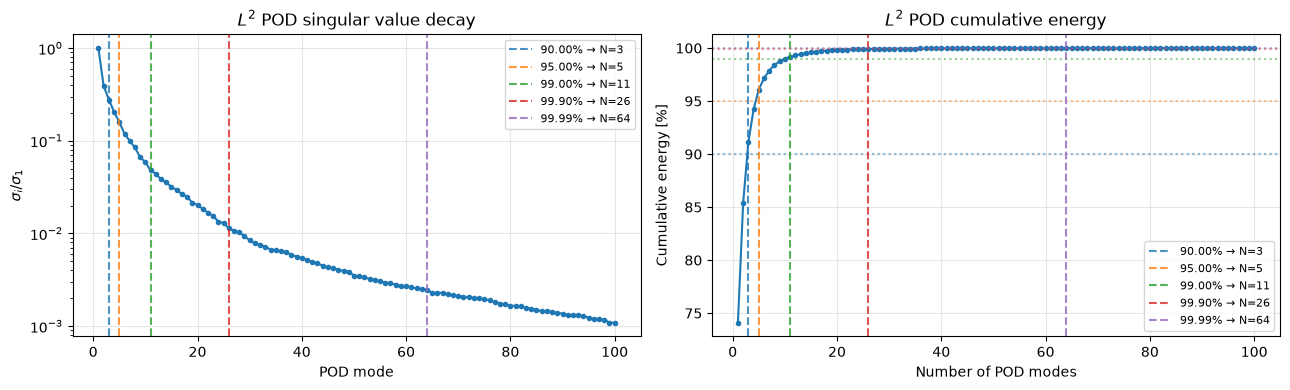

In [8]:
sf.plot_pod_analysis(s, total_energy=pod.total_energy)
clear_output(wait=True)

## Choice of the number of singular values

### Verification of the $M$-orthonormality of the POD basis

After selecting the reduced dimension $N$, the POD basis is truncated by retaining the first $N$ modes:

$$
V_N = [\phi_1,\phi_2,\ldots,\phi_N] \in \mathbb{R}^{N_h \times N}.
$$

Since the POD has been constructed consistently with the spatial $L^2$ inner product, orthogonality must be verified with respect to the corresponding finite-element mass matrix $M$, rather than using the standard Euclidean inner product.

For two finite-element functions represented by the coefficient vectors $\mathbf{u}$ and $\mathbf{v}$, the continuous $L^2$ inner product

$$
\langle u,v\rangle_{L^2(\Omega)}
=
\int_{\Omega} u(x)v(x)\,dx
$$

is represented after spatial discretization as

$$
\langle \mathbf{u},\mathbf{v}\rangle_M
=
\mathbf{u}^T M \mathbf{v},
$$

where $M$ is the finite-element mass matrix.

Therefore, an $L^2$-orthonormal POD basis must satisfy

$$
\phi_i^T M \phi_j = \delta_{ij},
$$

where $\delta_{ij}$ is the Kronecker delta. In matrix form, this condition becomes

$$
V_N^T M V_N = I_N.
$$

To verify this property numerically, the Gram matrix of the truncated basis is computed as

$$
G = V_N^T M V_N.
$$

For a perfectly $M$-orthonormal basis, $G$ would coincide with the identity matrix $I_N$. In floating-point arithmetic, however, small deviations from the identity are expected because of numerical round-off errors.

The overall deviation from orthonormality is measured through the Frobenius norm

$$
\|G-I_N\|_F
=
\sqrt{
\sum_{i=1}^{N}
\sum_{j=1}^{N}
\left(G_{ij}-\delta_{ij}\right)^2
}.
$$

This quantity accounts for the accumulated error over all entries of the Gram matrix. In addition, the maximum absolute entry-wise error is evaluated as

$$
\max_{i,j}
\left|G_{ij}-\delta_{ij}\right|,
$$

which measures the largest individual deviation from the expected orthonormality condition.

Values close to machine precision confirm that the computed POD modes are numerically orthonormal with respect to the $L^2$ inner product induced by $M$.

The reduced dimension is currently set to $N=26$, corresponding to the minimum number of POD modes required to capture at least $99.9\%$ of the snapshot energy. This choice will subsequently be validated through the projection-error analysis on unseen data.


In [9]:
n_modes = 26

if n_modes > V.shape[1]:
    raise ValueError("Requested modes exceed available modes")

Vn = V[:, :n_modes]

G = Vn.T @ (M @ Vn)
error_matrix = G - np.eye(n_modes)

print("M-orthonormality error (Frobenius):",
      np.linalg.norm(error_matrix, 'fro'))

print("Maximum absolute entry-wise error:",
      np.max(np.abs(error_matrix)))

M-orthonormality error (Frobenius): 7.305979823750094e-13
Maximum absolute entry-wise error: 4.0456527017340704e-13


### POD Projection Error

We project the validation snapshots onto the selected POD basis ($N=26$) and reconstruct the corresponding high-dimensional fields.

The relative spatial $L^2$ reconstruction error is computed using the FEM mass matrix:

$$
\varepsilon(t,\boldsymbol{\mu}) =
\frac{\|\mathbf{u}_h-\mathbf{u}_{POD}\|_M}
{\|\mathbf{u}_h\|_M},
\qquad
\|\mathbf{v}\|_M = \sqrt{\mathbf{v}^T M\mathbf{v}}.
$$

Mean, median and worst-trajectory errors quantify the **irreducible projection error** associated with the selected reduced space, independently of the neural network.

In [10]:
A_train = sf.project_l2(snapshots_train, Vn, M)
A_val = sf.project_l2(u_val.reshape(-1, N_h), Vn, M)
u_val_pod = sf.reconstruct_pod(A_val, Vn).reshape(u_val.shape)
projection_errors = sf.relative_l2_error(u_val, u_val_pod, M)
projection_summary = sf.summarize_errors(projection_errors)
print("POD validation projection error:")
print(f"  Mean:   {100 * projection_summary['mean_error']:.3f}%")
print(f"  Median: {100 * projection_summary['median_error']:.3f}%")
print(f"  Max:    {100 * projection_summary['worst_trajectory_error']:.3f}%")

POD validation projection error:
  Mean:   3.715%
  Median: 3.541%
  Max:    4.741%


### Sensitivity to POD Dimension

To assess the trade-off between accuracy and reduced-order complexity, we evaluate the validation projection error for different numbers of POD modes.

Three metrics are considered:
- **Mean error:** average relative error across trajectories (after time averaging).
- **Worst trajectory:** highest time-averaged error among validation trajectories.
- **Maximum snapshot error:** largest individual relative error across all validation snapshots.

The resulting error curves allow us to assess whether $N=26$ provides a suitable compromise between reconstruction accuracy and ROM complexity.

In [11]:
pod_errors = {}

for n in [3, 5, 10, 20, 26, 30, 50, 75, 100]:
    if n > V.shape[1]:
        continue

    basis = V[:, :n]

    a = sf.project_l2(u_val, basis, M)
    reconstruction = sf.reconstruct_pod(a, basis)

    errors = sf.relative_l2_error(u_val, reconstruction, M)
    summary = sf.summarize_errors(errors)

    pod_errors[n] = {
        'mean': summary['mean_error'],
        'worst_trajectory': summary['worst_trajectory_error'],
        'max_snapshot': summary['max_snapshot_error']
    }

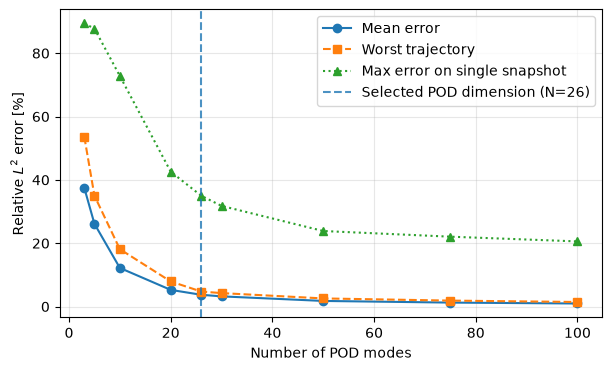

In [12]:
n_values = np.array(list(pod_errors.keys()))

mean_errors = 100 * np.array([
    pod_errors[n]['mean'] for n in n_values
])

worst_errors = 100 * np.array([
    pod_errors[n]['worst_trajectory'] for n in n_values
])

max_errors = 100 * np.array([
    pod_errors[n]['max_snapshot'] for n in n_values
])

plt.figure(figsize=(7, 4))

plt.plot(n_values, mean_errors, 'o-', label='Mean error')
plt.plot(n_values, worst_errors, 's--', label='Worst trajectory')
plt.plot(n_values, max_errors, '^:', label='Max error on single snapshot')

# Current POD dimension
plt.axvline(
    26,
    linestyle='--',
    alpha=0.8,
    label='Selected POD dimension (N=26)'
)

plt.xlabel('Number of POD modes')
plt.ylabel('Relative $L^2$ error [%]')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### POD Dimension Selection

The projection error decreases significantly as the number of POD modes increases, with the largest improvements occurring for small values of $N$.

Although $N=26$ provides a reasonable initial approximation, increasing the reduced dimension further improves the mean and worst-trajectory errors. However, the maximum single-snapshot error remains relatively high, even for $N=100$.

Therefore, we will also investigate **larger POD dimensions**, evaluating whether the additional reconstruction accuracy justifies the increased complexity of the neural network.

In [13]:
n_modes_study = [26, 30, 35, 40, 45, 50, 60, 75, 100]

print(f"{'N':>4} | {'Mean [%]':>10} | {'Worst traj. [%]':>15} | {'Max snapshot [%]':>16}")
print("-" * 56)

for n in n_modes_study:
    basis = V[:, :n]
    A_val = sf.project_l2(u_val, basis, M)
    u_val_pod = sf.reconstruct_pod(A_val, basis)

    summary = sf.summarize_errors(
        sf.relative_l2_error(u_val, u_val_pod, M)
    )

    print(f"{n:4d} | "
          f"{100*summary['mean_error']:10.3f} | "
          f"{100*summary['worst_trajectory_error']:15.3f} | "
          f"{100*summary['max_snapshot_error']:16.3f}")

   N |   Mean [%] | Worst traj. [%] | Max snapshot [%]
--------------------------------------------------------
  26 |      3.715 |           4.741 |           34.982
  30 |      3.213 |           4.245 |           31.782
  35 |      2.648 |           3.543 |           29.269
  40 |      2.262 |           3.310 |           27.772
  45 |      2.046 |           3.065 |           24.974
  50 |      1.770 |           2.562 |           23.849
  60 |      1.496 |           2.207 |           23.233
  75 |      1.249 |           1.876 |           22.060
 100 |      0.962 |           1.438 |           20.568


### Final POD Dimension Selection

To balance reconstruction accuracy and neural network complexity, we select **$N=50$ POD modes**, achieving a mean relative $L^2$ projection error lower than 2%.

Beyond this dimension, further improvements become relatively small, while the number of NN output neurons and trainable parameters increases. Thus, $N=50$ represents a reasonable trade-off between accuracy and computational efficiency.

In [14]:
# Redefine all necessary quantities with N = 50
n_modes = 50
Vn = V[:, :n_modes]

A_train = sf.project_l2(snapshots_train, Vn, M)
A_val = sf.project_l2(u_val, Vn, M)

u_val_pod = sf.reconstruct_pod(A_val, Vn)
projection_errors = sf.relative_l2_error(u_val, u_val_pod, M)

projection_summary = sf.summarize_errors(projection_errors)

print(f"Selected POD dimension: N = {n_modes}")
print(f"Validation projection error: {100 * projection_summary['mean_error']:.3f}%")

Selected POD dimension: N = 50
Validation projection error: 1.770%


### POD projection error over time

After selecting $N=50$ as a compromise between projection accuracy and reduced-space dimension, we analyze how the POD projection error evolves over time across the validation trajectories.

While the previous analysis provides an aggregate measure of the approximation accuracy, examining the temporal evolution of the error allows us to assess whether the POD representation performs consistently throughout the simulation or whether specific time regions are more difficult to approximate.

For each validation trajectory and time instant, the relative spatial $L^2$ projection error is evaluated as

$$
e_i(t_j)
=
\frac{
\left\|u_i(t_j)-\tilde{u}_i(t_j)\right\|_{L^2(\Omega)}
}{
\left\|u_i(t_j)\right\|_{L^2(\Omega)}
},
$$

where $u_i(t_j)$ is the FOM solution and $\tilde{u}_i(t_j)$ is its projection onto the POD space.

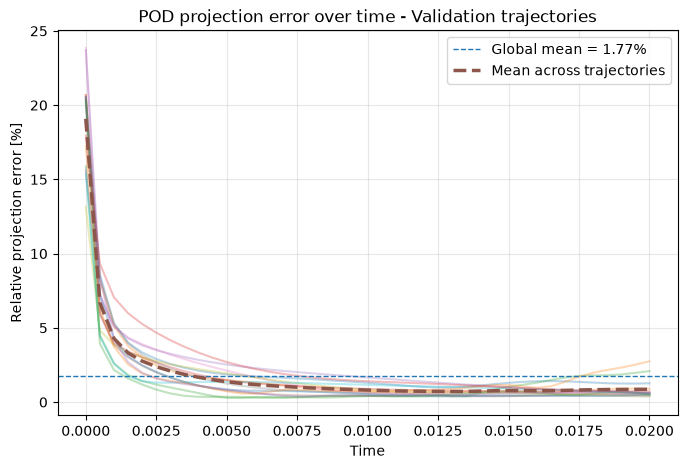

In [15]:
time_grid = np.linspace(0, T, N_t)

mean_error = 100 * projection_errors.mean()
mean_error_time = 100 * projection_errors.mean(axis=0)

plt.figure(figsize=(8, 5))

for errors in projection_errors:
    plt.plot(time_grid, 100 * errors, alpha=0.3)

# Global mean error
plt.axhline(
    y=mean_error,
    linestyle='--',
    linewidth=1,
    label=f"Global mean = {mean_error:.2f}%"
)

# Mean across validation trajectories at each time instant
plt.plot(
    time_grid,
    mean_error_time,
    linestyle='--',
    linewidth=2.5,
    label="Mean across trajectories"
)

plt.xlabel("Time")
plt.ylabel("Relative projection error [%]")
plt.title("POD projection error over time - Validation trajectories")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Analysis of the initial projection error

The temporal analysis of the POD projection error shows significantly larger relative errors during the initial transient, followed by a rapid decrease as the solution evolves.

Since the relative projection error is defined as

$$
e(t)
=
\frac{
\|u(t)-P_Nu(t)\|_{L^2(\Omega)}
}{
\|u(t)\|_{L^2(\Omega)}
},
$$

a large value of $e(t)$ can originate from two different effects: a genuinely large absolute projection error in the numerator, or a small solution norm in the denominator that amplifies an otherwise small approximation error.

To distinguish between these two effects, the numerator and denominator are analyzed separately. In particular, we consider the absolute POD projection error

$$
E_{\mathrm{abs}}(t)
=
\|u(t)-P_Nu(t)\|_{L^2(\Omega)}
$$

and the solution norm

$$
U(t)
=
\|u(t)\|_{L^2(\Omega)}.
$$

Their evolution is averaged across the validation trajectories and compared over time. This allows us to determine whether the large relative errors observed during the initial transient are primarily caused by poor POD representation or by the normalization used in the relative-error metric.

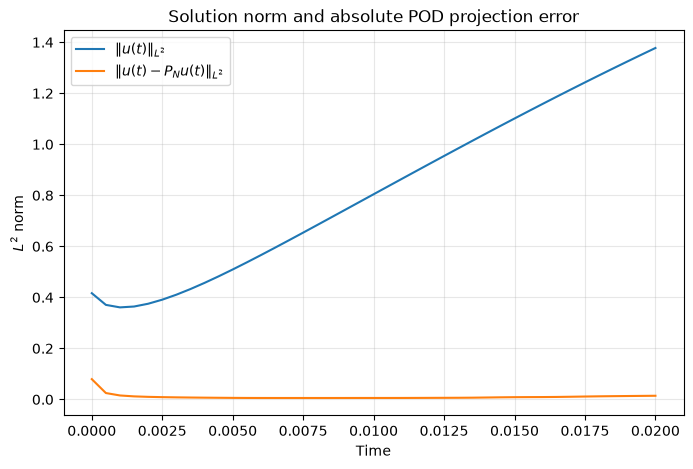

In [16]:
solution_norm = sf.l2_norm(u_val, M)
absolute_error = sf.l2_norm(u_val - u_val_pod, M)

mean_solution_norm = solution_norm.mean(axis=0)
mean_absolute_error = absolute_error.mean(axis=0)

plt.figure(figsize=(8, 5))

plt.plot(time_grid, mean_solution_norm, label=r'$\|u(t)\|_{L^2}$')
plt.plot(time_grid, mean_absolute_error, label=r'$\|u(t)-P_Nu(t)\|_{L^2}$')

plt.xlabel("Time")
plt.ylabel(r"$L^2$ norm")
plt.title("Solution norm and absolute POD projection error")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Interpretation of the projection error evolution

The comparison between the solution norm and the absolute POD projection error provides additional insight into the temporal behavior of the relative error.

During the initial transient, the large relative projection error is mainly associated with an actual increase in the absolute approximation error,

$$
E_{\mathrm{abs}}(t)
=
\|u(t)-P_Nu(t)\|_{L^2(\Omega)},
$$

rather than with an amplification caused by a vanishing denominator. Indeed, the solution norm $\|u(t)\|_{L^2(\Omega)}$ remains finite during the initial time interval, whereas the absolute projection error rapidly decreases.

This behavior can be related to the underlying Fisher-KPP dynamics. During the early stages of the simulation, the solution undergoes a rapid transient characterized by localized spatial structures and relatively sharp gradients. Such features generally require a richer combination of spatial modes to be accurately represented. As the reaction-diffusion process evolves and the propagation front develops, the solution enters a regime that is more effectively represented by the dominant POD modes. Consequently, the absolute and relative projection errors rapidly decrease and remain approximately stationary for most of the simulation.

A smaller but noticeable increase in the absolute projection error is also observed toward the end of the considered time interval. Contrary to the initial peak, this behavior cannot be attributed to the normalization of the relative error, since the $L^2$ norm of the solution continues to increase. Instead, it suggests a slight deterioration of the ability of the fixed reduced basis to represent the spatial configurations reached at later stages of the propagation process. As the front evolves through the domain, new spatial configurations may become relatively less represented by the dominant POD modes retained in the $N=50$ basis.

However, this late-time effect is considerably weaker than the initial transient and does not indicate a general loss of accuracy of the reduced representation. Overall, the selected POD space provides an accurate approximation throughout most of the temporal evolution, while the largest projection errors are concentrated in the rapidly evolving initial phase.

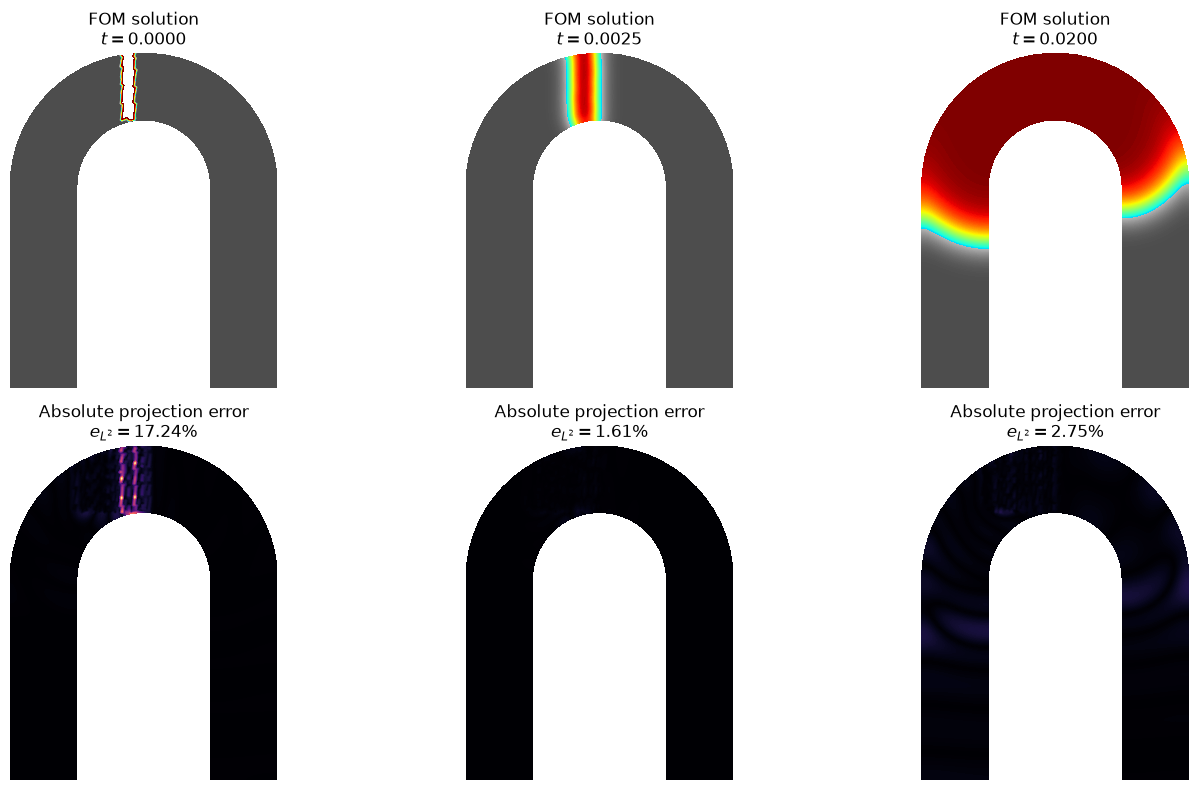

Representative trajectory: 11
Parameters: [0.28605382 0.95810557 0.77031293]
Mean projection error: 1.780%


In [17]:
# Representative validation trajectory
trajectory_errors = projection_errors.mean(axis=1)
idx = np.argmin(np.abs(trajectory_errors - trajectory_errors.mean()))

# Times of interest
times_to_plot = [0.0, 0.0025, T]
time_indices = [
    np.argmin(np.abs(time_grid - t))
    for t in times_to_plot
]

# FOM and POD projection
u_traj = u_val[idx]
u_pod_traj = u_val_pod[idx]
abs_error = np.abs(u_traj - u_pod_traj)

# Common scales within each row
u_min, u_max = u_traj.min(), u_traj.max()
error_max = abs_error[time_indices].max()

cmap = sf.modify_jet_to_gray()

plt.figure(figsize=(15, 8))

for k, j in enumerate(time_indices):

    # FOM solution
    plt.subplot(2, 3, k + 1)
    fe.plot(
        u_traj[j],
        Vh,
        vmin=u_min,
        vmax=u_max,
        cmap=cmap
    )
    plt.title(
        f"FOM solution\n"
        f"$t={time_grid[j]:.4f}$"
    )

    # Pointwise absolute projection error
    plt.subplot(2, 3, k + 4)
    fe.plot(
        abs_error[j],
        Vh,
        vmin=0,
        vmax=error_max,
        cmap="magma"
    )
    plt.title(
        f"Absolute projection error\n"
        f"$e_{{L^2}}={100*projection_errors[idx, j]:.2f}\\%$"
    )

plt.tight_layout()
plt.show()

print(f"Representative trajectory: {idx}")
print(f"Parameters: {mu_val[idx]}")
print(f"Mean projection error: {100*trajectory_errors[idx]:.3f}%")

### Physical interpretation of the POD projection error

The spatial distribution of the FOM solution and of the corresponding pointwise projection error provides a physical interpretation of the temporal error behavior observed above.

The damage propagation is governed by the Fisher-KPP equation

$$
\frac{\partial u}{\partial t}
=
D\Delta u + ru(1-u),
$$

where the two terms on the right-hand side describe two complementary mechanisms. The diffusion term $D\Delta u$ spreads the damage spatially and smooths sharp gradients, while the nonlinear reaction term $ru(1-u)$ promotes damage growth wherever $0<u<1$. Their combined action generates a propagating reaction-diffusion front through the U-bolt.

At the initial time, the prescribed damage field is highly localized:

$$
g_\delta(x,y)=
\begin{cases}
1, & |x-\delta|<0.1,\; y\geq4,\\
0, & \text{otherwise}.
\end{cases}
$$

The solution therefore contains sharp transitions between damaged and undamaged regions. Moreover, the location $\delta$ of this localized structure varies across the parameter space. From a MOR perspective, this represents a challenging configuration for a linear POD approximation: a fixed global basis must reproduce sharp localized structures appearing at different spatial locations using linear combinations of the same modes. Consequently, a relatively large number of modes may be required to accurately represent this initial family of states. This is consistent with the spatial error map at $t=0$, where the projection error is strongly concentrated around the boundaries of the initial damaged region.

During the initial transient, diffusion progressively smooths these sharp spatial gradients. At the same time, diffusion creates regions where $0<u<1$, in which the reaction term is positive and promotes further damage growth. The interaction of these mechanisms produces the characteristic Fisher-KPP propagation front. By $t=0.0025$, the initially localized structure has evolved into a smoother and more spatially extended configuration, and the relative projection error decreases from approximately $17.2\%$ to $1.6\%$ for the representative trajectory.

This provides a direct connection between the physics of the PDE and the performance of the reduced representation: as the solution evolves away from the sharply localized initial condition, its spatial structure becomes more efficiently represented by the dominant global POD modes.

At later times, a smaller increase in projection error is observed. At $t=0.02$, the damage front has propagated through a substantial portion of the U-shaped domain and the error is mainly distributed around the evolving front. Since the $L^2$ norm of the solution is large and increasing in this regime, this behavior cannot be attributed to the normalization of the relative error. Instead, it indicates that the spatial configurations associated with the later stages of front propagation are slightly less accurately represented by the fixed $N=50$ POD subspace. Nevertheless, this effect is considerably weaker than the initial transient.

Overall, the analysis highlights an important connection between the underlying physics and the MOR approximation. The most challenging states for the POD basis are associated with localized and moving spatial features, whereas the smoother intermediate propagation regime admits a considerably more compact linear representation. The selected $N=50$ basis therefore provides a good compromise: it substantially improves the representation of these more demanding states while retaining a relatively low-dimensional reduced space for the subsequent neural-network surrogate.

***

## Neural Network design and training

### POD-NN: Neural network approximation of the reduced dynamics

Having constructed and validated the POD basis, we now proceed to the development of a **POD-NN reduced-order model**. The objective is to replace the expensive FOM simulations with a neural-network surrogate capable of predicting the solution for arbitrary parameter configurations and time instants.

The POD analysis identified a reduced dimension of $N=50$ as a suitable compromise between projection accuracy and reduced-space complexity. The full-order solution is therefore approximated as

$$
\mathbf{u}(\boldsymbol{\mu},t)
\approx
V_N\mathbf{a}(\boldsymbol{\mu},t),
$$

where $V_N\in\mathbb{R}^{N_h\times N}$ is the fixed POD basis and $\mathbf{a}(\boldsymbol{\mu},t)\in\mathbb{R}^{N}$ contains the corresponding reduced coefficients.

Rather than learning the full-order solution directly, the neural network is trained to approximate the mapping

$$
\mathcal{N}_{\theta}:
(\boldsymbol{\mu},t/T)
\longmapsto
\hat{\mathbf{a}}(\boldsymbol{\mu},t).
$$

The resulting POD-NN approximation is then reconstructed as

$$
\tilde{\mathbf{u}}(\boldsymbol{\mu},t)
=
V_N\mathcal{N}_{\theta}(\boldsymbol{\mu},t/T).
$$

This approach separates the spatial compression performed by POD from the nonlinear regression performed by the neural network. The network has four inputs (three physical parameters and normalized time) and $N=50$ outputs, substantially reducing the dimensionality compared with a direct prediction of the $N_h=6636$ FOM degrees of freedom.

#### Preparation of training and validation data

Each FOM trajectory corresponds to a fixed parameter vector $\boldsymbol{\mu}$ and contains $N_t=41$ temporal snapshots. To construct the supervised learning dataset, every parameter vector is paired with each time instant, producing one input sample per snapshot:

$$
\mathbf{x}_{i,j}
=
\begin{bmatrix}
\mu_{i,1} & \mu_{i,2} & \mu_{i,3} & t_j/T
\end{bmatrix}.
$$

The target outputs are obtained by projecting the corresponding FOM snapshots onto the previously computed POD basis. Since the basis is orthonormal with respect to the finite-element mass matrix $M$, the projection coefficients are

$$
\mathbf{a}_{i,j}
=
V_N^T M\mathbf{u}_{i,j}.
$$

Equivalently, collecting snapshots as rows in a matrix $S$, the coefficient matrix is

$$
A=SMV_N.
$$

The POD basis is computed exclusively from the training trajectories and remains fixed throughout the neural-network training and validation process. Validation snapshots are projected onto this same basis, avoiding information leakage.

The time coordinate is normalized to $[0,1]$ to improve the numerical conditioning of neural-network training. The reduced coefficients will also be scaled using statistics computed exclusively from the training set.

Finally, the neural network will be optimized to minimize the discrepancy between predicted and reference POD coefficients. Because the basis is $M$-orthonormal, the Euclidean error in the reduced coefficients corresponds to the spatial $L^2$ error between their reconstructed fields. This allows the network to be trained directly in the reduced space while preserving consistency with the spatial norm used throughout the POD analysis.

The final model will be evaluated on unseen trajectories using the relative spatial $L^2$ error defined in the assignment, allowing the additional neural-network approximation error to be distinguished from the intrinsic POD projection error.

In [19]:
# Selected POD basis
n_modes = 50
Vn = V[:, :n_modes]

# NN inputs: [mu1, mu2, mu3, t/T]
X_train_nn = sf.make_nn_inputs(mu_train, time_grid)
X_val_nn = sf.make_nn_inputs(mu_val, time_grid)

# L2-projected POD coefficients
A_train = sf.project_l2(u_train.reshape(-1, N_h), Vn, M)
A_val = sf.project_l2(u_val.reshape(-1, N_h), Vn, M)

# Coefficient normalization fitted on training data only
scaler = sf.fit_coefficient_scaler(A_train)

print("X train:", X_train_nn.shape)
print("A train:", A_train.shape)
print("X val:  ", X_val_nn.shape)
print("A val:  ", A_val.shape)

assert X_train_nn.shape == (len(mu_train) * N_t, 4)
assert A_train.shape == (len(X_train_nn), n_modes)
assert X_val_nn.shape == (len(mu_val) * N_t, 4)
assert A_val.shape == (len(X_val_nn), n_modes)

X train: (2460, 4)
A train: (2460, 50)
X val:   (615, 4)
A val:   (615, 50)


### Neural network architecture and hyperparameter selection

Having constructed and validated the POD basis, we now develop a neural-network surrogate to approximate the reduced coefficients as functions of the physical parameters and time.

The POD-NN approximates the mapping

$$
\mathcal{N}_{\theta}:
\mathbb{R}^{4}\rightarrow\mathbb{R}^{50},
\qquad
(\boldsymbol{\mu},t/T)\mapsto\hat{\mathbf a},
$$

where $\boldsymbol{\mu}\in\mathbb{R}^3$ contains the physical parameters, $t/T$ is the normalized time coordinate, and $\hat{\mathbf a}\in\mathbb{R}^{50}$ represents the predicted POD coefficients.

We employ a fully connected feedforward neural network (multilayer perceptron, MLP), consisting of an input layer, several hidden layers with nonlinear activation functions, and a linear output layer. The trainable parameters $\theta$ are the network weights and biases, optimized through backpropagation.

The main hyperparameters considered are:

- **Network depth:** number of hidden layers, controlling the complexity of the nonlinear mapping.
- **Network width:** number of neurons per hidden layer, determining the representational capacity of the network.
- **Activation function:** introduces nonlinearity and influences optimization and approximation properties. LeakyReLU, Tanh, and SiLU are considered.
- **Learning rate:** controls the magnitude of parameter updates during optimization.
- **Weight decay:** introduces regularization to limit excessive model complexity and improve generalization.
- **Batch size:** determines the number of training samples used for each optimizer update.
- **Training duration and learning-rate scheduling:** determine how long the network is trained and how the learning rate adapts during optimization.

#### Training objective and consistency with the spatial $L^2$ norm

The network predicts normalized POD coefficients to improve numerical conditioning. However, the loss function is evaluated after transforming the predictions back to their original coefficient scale, ensuring consistency with the spatial $L^2$ norm.

Since the POD basis is orthonormal with respect to the finite-element mass matrix $M$,

$$
V_N^T M V_N=I_N,
$$

the following identity holds:

$$
\|V_N\mathbf a-V_N\hat{\mathbf a}\|_{L^2(\Omega)}^2
=
\|\mathbf a-\hat{\mathbf a}\|_2^2.
$$

Therefore, minimizing the squared Euclidean error between the unscaled POD coefficients is equivalent to minimizing the squared spatial $L^2$ error between their reconstructed fields.

The training objective is defined as

$$
\mathcal L(\theta)
=
\frac{1}{N_s}
\sum_{s=1}^{N_s}
\|\mathbf a_s-\hat{\mathbf a}_s(\theta)\|_2^2,
$$

where $N_s$ is the number of training snapshots. In the implementation, the loss is additionally averaged over the $N=50$ coefficient components, introducing only a constant scaling factor that does not affect its minimizer.

#### Validation metric and error decomposition

While the training loss measures the accuracy of the reduced-coefficient regression, the predictive performance of the complete POD-NN is assessed against the original FOM solutions.

Following the assignment requirements, the validation metric is the mean relative spatial $L^2$ error, averaged first over time and then over the validation trajectories:

$$
E_{\mathrm{val}}
=
\frac{1}{N_{\mathrm{val}}}
\sum_{i=1}^{N_{\mathrm{val}}}
\left[
\frac{1}{N_t}
\sum_{j=1}^{N_t}
\frac{
\|\mathbf u_{i,j}-\tilde{\mathbf u}_{i,j}\|_{L^2(\Omega)}
}{
\|\mathbf u_{i,j}\|_{L^2(\Omega)}
}
\right],
$$

where the reconstructed POD-NN solution is

$$
\tilde{\mathbf u}_{i,j}
=
V_N\hat{\mathbf a}_{i,j}.
$$

Unlike the coefficient-space training loss, this metric measures the total approximation error of the ROM, including both POD truncation and neural-network regression errors.

Because the POD projection is orthogonal with respect to the $M$-inner product, the squared reconstruction error can be decomposed as

$$
\|\mathbf u-\tilde{\mathbf u}\|_{L^2(\Omega)}^2
=
\underbrace{
\|\mathbf u-P_N\mathbf u\|_{L^2(\Omega)}^2
}_{\text{POD projection error}}
+
\underbrace{
\|\mathbf a-\hat{\mathbf a}\|_2^2
}_{\text{NN regression error}},
$$

where $P_N\mathbf u=V_N\mathbf a$ denotes the orthogonal POD projection.

This decomposition shows that the previously measured POD projection error represents an irreducible approximation floor for the selected reduced space. The neural network introduces an additional regression error, which we aim to minimize through training and hyperparameter selection.

During training, the coefficient-space training and validation losses are monitored to assess convergence and potential overfitting. The mean relative spatial $L^2$ error is used as the primary criterion for comparing the predictive performance of candidate models.

#### Sequential hyperparameter tuning

Rather than performing an exhaustive grid search over all hyperparameter combinations, we adopt a sequential tuning strategy. This reduces computational cost and allows us to interpret the influence of individual design choices.

The procedure consists of the following stages:

1. **Baseline model:** establish a reference architecture using LeakyReLU, Adam, a learning rate of $10^{-3}$, and a fixed batch size.
2. **Architecture selection:** compare a limited set of network depths and widths while keeping the remaining training settings fixed.
3. **Optimization and regularization:** investigate the learning rate and weight decay for the most promising architectures.
4. **Activation function:** compare LeakyReLU, Tanh, and SiLU using the selected architecture and optimization settings.
5. **Training stability:** repeat the final configuration with different random seeds to assess sensitivity to initialization and stochastic training.

All configurations are evaluated using the same training-validation split and the fixed $N=50$ POD basis. The POD basis and coefficient normalization parameters are computed exclusively from the training data, avoiding information leakage from validation and test trajectories.

For each experiment, we monitor the training and validation losses and evaluate the mean relative spatial $L^2$ error on the validation trajectories. Since hyperparameters can interact, sequential tuning does not guarantee a globally optimal configuration. Nevertheless, it provides a computationally manageable and interpretable approach to identifying a sufficiently accurate surrogate.

Once the hyperparameters have been selected, the final model will be evaluated on the previously unseen test trajectories, which remain excluded from the entire tuning process.

In [22]:
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

baseline_config = {
    "hidden_layers": (64, 64, 64),
    "activation": "leaky_relu",
    "lr": 1e-3,
    "weight_decay": 0.0,
    "batch_size": 64,
    "max_epochs": 1500,
}

Device: cpu


### Baseline Neural Network Training

We train a baseline neural network to learn the mapping from the physical parameters and time to the $N=50$ POD coefficients.

The experiment uses the predefined baseline configuration and evaluates the trained model on the validation set using the relative spatial $L^2$ error.

The `run_cached_experiment()` function also saves and reuses previously trained models, avoiding unnecessary retraining.

In [23]:
baseline = sf.run_cached_experiment(
    baseline_config,
    X_train_nn, A_train,
    X_val_nn, A_val,
    scaler, u_val, Vn, M,
    model_dir="models",
    device=device
)

baseline_model = baseline["model"]

Training already exists — loading checkpoint
Parameters: 11,890 | Best epoch: 1394
Validation coefficient MSE: 8.320007e-05
Mean relative L2: 8.022% | Worst trajectory: 16.872% | Max snapshot: 49.569%


### Baseline Training Convergence

We examine the evolution of the training and validation losses across epochs to assess the **convergence and generalization** of the baseline POD-NN.

Comparing the two curves helps identify potential overfitting, underfitting, and whether additional training epochs could improve performance.

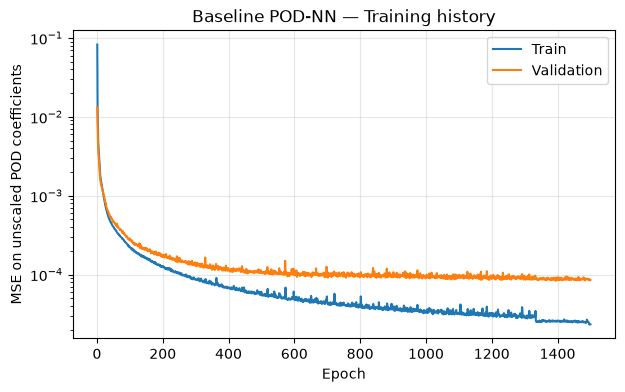

In [24]:
ax = sf.plot_training_history(
    baseline["train_history"],
    baseline["val_history"]
)

ax.set_title("Baseline POD-NN — Training history")
plt.show()


### Baseline POD-NN — Training Convergence

Both training and validation losses decrease rapidly during the initial epochs, followed by progressively slower convergence. The validation loss eventually stabilizes around $10^{-4}$, while the training loss continues to decrease, reaching approximately $2.5 \times 10^{-5}$.

The growing separation between the two curves indicates a **moderate generalization gap**, although the validation loss remains stable without a sustained upward trend. This suggests diminishing returns from additional training rather than severe overfitting.

Overall, the baseline appears to have reached a validation performance plateau, motivating further investigation of the **network architecture and training hyperparameters** rather than simply increasing the number of epochs.



### Hyperparameter Tuning — Network Width and Depth

The first tuning stage investigates the influence of the network architecture on POD-NN accuracy by varying the **width** (neurons per hidden layer) and **depth** (number of hidden layers), while keeping the remaining training hyperparameters fixed.

Smaller architectures with **16 and 32 neurons and 2 hidden layers** are excluded from the search, as preliminary experiments showed inferior performance compared to larger networks.

Each configuration is trained independently and evaluated on the same validation set using the relative spatial $L^2$ error. The results are compared in terms of **mean validation error, worst-case error, number of trainable parameters, and computational cost**, allowing us to identify a suitable trade-off between predictive accuracy and model complexity.



In [25]:
# Initial sequential architecture search
architectures = [
    (64, 3),    # Baseline
    (64, 4),    # Increased depth
    (128, 3), 
    (256, 3),  # Increased width
    (128, 4), 
    (128, 5),  # Increased width and depth
]

excel_path = Path("tuning_results.xlsx")
sheet_name = "architecture"

architecture_results = {}
rows = []

for width, depth in architectures:
    name = f"W{width}_D{depth}"
    print(f"\n{'='*60}\n{name}\n{'='*60}")

    config = {
        "hidden_layers": (width,) * depth,
        "activation": "leaky_relu",
        "lr": 1e-3,
        "weight_decay": 0.0,
        "batch_size": 64,
        "max_epochs": 1500,
        "seed": 42,
    }


    result = sf.run_cached_experiment(
        config,
        X_train_nn, A_train,
        X_val_nn, A_val,
        scaler, u_val, Vn, M,
        model_dir="models",
        device=device,
    )

    architecture_results[name] = result

    rows.append({
        "Experiment ID": result["experiment_id"],
        "Width": width,
        "Depth": depth,
        "Activation": config["activation"],
        "Learning rate": config["lr"],
        "Weight decay": config["weight_decay"],
        "Batch size": config["batch_size"],
        "Max epochs": config["max_epochs"],
        "Seed": config["seed"],
        "Parameters": result["parameters"],
        "Best epoch": result["best_epoch"],
        "Coefficient MSE": result["best_val_loss"],
        "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
        "Worst trajectory [%]": 100 * result["metrics"]["worst_trajectory_error"],
        "Max snapshot [%]": 100 * result["metrics"]["max_snapshot_error"],
        "Checkpoint": result["checkpoint_path"],
    })

    # Save incrementally after each experiment
    new_df = pd.DataFrame([rows[-1]])

    if excel_path.exists():
        workbook = load_workbook(excel_path, read_only=True)
        sheet_exists = sheet_name in workbook.sheetnames
        workbook.close()

        if sheet_exists:
            old_df = pd.read_excel(excel_path, sheet_name=sheet_name)
            new_df = pd.concat([old_df, new_df], ignore_index=True)

    # Update existing experiments, preserving all other results
    new_df = (
        new_df
        .drop_duplicates(subset="Experiment ID", keep="last")
        .sort_values("Mean L2 [%]")
        .reset_index(drop=True)
    )

    mode = "a" if excel_path.exists() else "w"
    writer_kwargs = (
        {"mode": "a", "if_sheet_exists": "replace"}
        if mode == "a" else {"mode": "w"}
    )

    with pd.ExcelWriter(
        excel_path, engine="openpyxl", **writer_kwargs
    ) as writer:
        new_df.to_excel(writer, sheet_name=sheet_name, index=False)

# Load complete architecture history
architecture_df = pd.read_excel(
    excel_path, sheet_name=sheet_name
).sort_values("Mean L2 [%]").reset_index(drop=True)

display(architecture_df.round(4))
print(f"\nResults saved to: {excel_path.resolve()}")


W64_D3
Training already exists — loading checkpoint
Parameters: 11,890 | Best epoch: 1394
Validation coefficient MSE: 8.320007e-05
Mean relative L2: 8.022% | Worst trajectory: 16.872% | Max snapshot: 49.569%

W64_D4
Training already exists — loading checkpoint
Parameters: 16,050 | Best epoch: 1388
Validation coefficient MSE: 5.412227e-05
Mean relative L2: 6.288% | Worst trajectory: 10.503% | Max snapshot: 42.932%

W128_D3
Training already exists — loading checkpoint
Parameters: 40,114 | Best epoch: 728
Validation coefficient MSE: 6.386017e-05
Mean relative L2: 6.726% | Worst trajectory: 9.965% | Max snapshot: 65.826%

W256_D3
Training already exists — loading checkpoint
Parameters: 145,714 | Best epoch: 678
Validation coefficient MSE: 7.605900e-05
Mean relative L2: 6.000% | Worst trajectory: 11.650% | Max snapshot: 56.537%

W128_D4
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 885
Validation coefficient MSE: 3.770805e-05
Mean relative L2: 5.322% | Worst

,Experiment ID,Width,Depth,Activation,Learning rate,Weight decay,Batch size,Max epochs,Seed,Parameters,Best epoch,Coefficient MSE,Mean L2 [%],Worst trajectory [%],Max snapshot [%],Checkpoint
0,a9cae18c7a0c57ac,128,5,leaky_relu,0.001,0.0,64.0,1500.0,42.0,73138,646,0.0000,5.2493,9.3687,47.7306,models/podnn_N50_W128_D5_leaky_relu_lr1e-03_wd...
1,d00b618a60f1051f,128,4,leaky_relu,0.001,0.0,64.0,1500.0,42.0,56626,885,0.0000,5.3217,10.2287,42.4101,models/podnn_N50_W128_D4_leaky_relu_lr1e-03_wd...
2,8b9c228277c672d9,256,3,leaky_relu,0.001,0.0,64.0,1500.0,42.0,145714,678,0.0001,5.9998,11.6497,56.5368,models/podnn_N50_W256_D3_leaky_relu_lr1e-03_wd...
3,d8753df1b6104f60,64,4,leaky_relu,0.001,0.0,64.0,1500.0,42.0,16050,1388,0.0001,6.2883,10.5028,42.9319,models/podnn_N50_W64_D4_leaky_relu_lr1e-03_wd0...
4,eb9a6810c0b61060,128,3,leaky_relu,0.001,0.0,64.0,1500.0,42.0,40114,728,0.0001,6.7258,9.9646,65.8263,models/podnn_N50_W128_D3_leaky_relu_lr1e-03_wd...
5,fa5b7e642560ab38,64,3,leaky_relu,0.001,0.0,64.0,1500.0,42.0,11890,1394,0.0001,8.0219,16.8720,49.5693,models/podnn_N50_W64_D3_leaky_relu_lr1e-03_wd0...
6,86806b148200c7b2,64,3,NaN,NaN,NaN,NaN,NaN,NaN,11890,1457,0.0015,38.1393,53.4503,117.7397,models/podnn_N50_W64_D3_silu_lr1e-03_wd1e-04_b...



Results saved to: /mnt/c/Users/Feder/Desktop/Master Courses/MOR/Python/Assignment2/tuning_results.xlsx



### Hyperparameter Tuning — Weight Decay

Following the architecture search, we investigate the effect of **weight decay**, which introduces $L^2$ regularization on the network weights to discourage overly complex solutions and potentially improve generalization.

The search is restricted to two architectures, **128 × 4** and **128 × 5**, which achieved the lowest mean relative $L^2$ validation errors (5.32% and 5.25%, respectively). Although the deeper network provides slightly better accuracy, it requires approximately 29% more trainable parameters (73,138 vs. 56,626). Both configurations are therefore retained to assess whether regularization changes their relative performance and to evaluate the trade-off between accuracy and model complexity.

Weight decay values of $10^{-6}$, $10^{-5}$ and $10^{-4}$ are tested, together with the previously trained unregularized models ($\lambda = 0$) as references. All other training hyperparameters are kept fixed to isolate the effect of regularization.

Model selection remains based primarily on the **mean relative $L^2$ validation error**, with worst-trajectory performance and model complexity considered as additional criteria.


In [26]:
# Selected architectures from previous tuning
architectures = [
    (128, 4),
    (128, 5),
]

# Include the unregularized reference models
weight_decays = [0.0, 1e-6, 1e-5, 1e-4]

excel_path = Path("tuning_results.xlsx")
sheet_name = "weight_decay"

weight_decay_results = {}
rows = []

for width, depth in architectures:
    for wd in weight_decays:
        name = f"W{width}_D{depth}_WD{wd:.0e}"
        print(f"\n{'='*60}\n{name}\n{'='*60}")

        config = {
            "hidden_layers": (width,) * depth,
            "activation": "silu",
            "lr": 3e-3,
            "weight_decay": wd,
            "batch_size": 64,
            "max_epochs": 1500,
            "seed": 42,
        }

        result = sf.run_cached_experiment(
            config,
            X_train_nn, A_train,
            X_val_nn, A_val,
            scaler, u_val, Vn, M,
            model_dir="models",
            device=device,
        )

        weight_decay_results[name] = result

        row = {
            "Experiment ID": result["experiment_id"],
            "Width": width,
            "Depth": depth,
            "Activation": config["activation"],
            "Learning rate": config["lr"],
            "Weight decay": wd,
            "Batch size": config["batch_size"],
            "Max epochs": config["max_epochs"],
            "Seed": config["seed"],
            "Parameters": result["parameters"],
            "Best epoch": result["best_epoch"],
            "Coefficient MSE": result["best_val_loss"],
            "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
            "Worst trajectory [%]": 100 * result["metrics"]["worst_trajectory_error"],
            "Max snapshot [%]": 100 * result["metrics"]["max_snapshot_error"],
            "Checkpoint": result["checkpoint_path"],
        }
        rows.append(row)

        # Save results immediately after each experiment
        new_df = pd.DataFrame([row])

        if excel_path.exists():
            workbook = load_workbook(excel_path, read_only=True)
            sheet_exists = sheet_name in workbook.sheetnames
            workbook.close()

            if sheet_exists:
                old_df = pd.read_excel(
                    excel_path, sheet_name=sheet_name
                )
                new_df = pd.concat(
                    [old_df, new_df], ignore_index=True
                )

        new_df = (
            new_df
            .drop_duplicates(
                subset="Experiment ID", keep="last"
            )
            .sort_values("Mean L2 [%]")
            .reset_index(drop=True)
        )

        if excel_path.exists():
            writer_kwargs = {
                "mode": "a",
                "if_sheet_exists": "replace",
            }
        else:
            writer_kwargs = {"mode": "w"}

        with pd.ExcelWriter(
            excel_path,
            engine="openpyxl",
            **writer_kwargs,
        ) as writer:
            new_df.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )

            # Apply readable Excel number formats
            ws = writer.sheets[sheet_name]
            ws.freeze_panes = "A2"
            ws.auto_filter.ref = ws.dimensions

            for col in ws.columns:
                header = col[0].value

                if header in ("Learning rate", "Weight decay",
                              "Coefficient MSE"):
                    for cell in col[1:]:
                        cell.number_format = "0.00E+00"

                elif header in ("Mean L2 [%]",
                                "Worst trajectory [%]",
                                "Max snapshot [%]"):
                    for cell in col[1:]:
                        cell.number_format = "0.0000"

# Complete tuning history, including previous runs
weight_decay_df = (
    pd.read_excel(excel_path, sheet_name=sheet_name)
    .sort_values("Mean L2 [%]")
    .reset_index(drop=True)
)


print(
    weight_decay_df.to_string(
        index=False,
        formatters={
            "Learning rate": lambda x: f"{x:.1e}",
            "Weight decay": lambda x: f"{x:.1e}",
            "Coefficient MSE": lambda x: f"{x:.3e}",
            "Mean L2 [%]": lambda x: f"{x:.4f}",
            "Worst trajectory [%]": lambda x: f"{x:.4f}",
            "Max snapshot [%]": lambda x: f"{x:.4f}",
        },
        na_rep="—",
    )
)

print(f"\nResults saved to: {excel_path.resolve()}")



W128_D4_WD0e+00
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 926
Validation coefficient MSE: 1.428325e-05
Mean relative L2: 3.176% | Worst trajectory: 4.667% | Max snapshot: 37.802%

W128_D4_WD1e-06
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1491
Validation coefficient MSE: 4.908385e-05
Mean relative L2: 6.152% | Worst trajectory: 9.218% | Max snapshot: 52.576%

W128_D4_WD1e-05
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 887
Validation coefficient MSE: 2.267709e-04
Mean relative L2: 13.980% | Worst trajectory: 18.215% | Max snapshot: 76.515%

W128_D4_WD1e-04
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1456
Validation coefficient MSE: 1.216930e-03
Mean relative L2: 34.570% | Worst trajectory: 48.772% | Max snapshot: 104.427%

W128_D5_WD0e+00
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1212
Validation coefficient MSE: 8

### Weight Decay Regularization Assessment

We investigated the effect of $L_2$ weight decay regularization on the baseline POD-NN.

The tested values ($10^{-6}$, $10^{-5}$ and $10^{-4}$) resulted in higher validation coefficient MSE and mean relative $L^2$ errors compared to the unregularized baseline (5.32%, 6.25%, and 11.55%, respectively).

Since weight decay did not improve the overall predictive accuracy, we retain the **baseline configuration with weight decay = 0** for subsequent experiments.

### Hyperparameter Tuning - Learning Rate

We investigate the effect of the learning rate on the convergence and predictive accuracy of the POD-NN.

Starting from the baseline value of $\eta = 10^{-3}$, we test two additional configurations:

- **$\eta = 3 \times 10^{-3}$:** to explore faster convergence.
- **$\eta = 3 \times 10^{-4}$:** to assess whether smaller optimization steps improve stability and final accuracy.

All other hyperparameters are kept unchanged to isolate the effect of the learning rate. The configurations are compared based on validation errors and training convergence.

In [27]:
from openpyxl.utils import get_column_letter

# Selected architectures from previous tuning
architectures = [
    (128, 4),
    (128, 5),
]

# Learning rate search, including the baseline
learning_rates = [3e-4, 1e-3, 3e-3]

excel_path = Path("tuning_results.xlsx")
sheet_name = "learning_rate"

learning_rate_results = {}

for width, depth in architectures:
    for lr in learning_rates:
        name = f"W{width}_D{depth}_LR{lr:.1e}"

        print(f"\n{'='*60}\n{name}\n{'='*60}")

        config = {
            "hidden_layers": (width,) * depth,
            "activation": "silu",
            "lr": lr,
            "weight_decay": 0.0,
            "batch_size": 64,
            "max_epochs": 1500,
            "seed": 42,
        }

        result = sf.run_cached_experiment(
            config,
            X_train_nn, A_train,
            X_val_nn, A_val,
            scaler, u_val, Vn, M,
            model_dir="models",
            device=device,
        )

        learning_rate_results[name] = result

        row = {
            "Experiment ID": result["experiment_id"],
            "Width": width,
            "Depth": depth,
            "Activation": config["activation"],
            "Learning rate": config["lr"],
            "Weight decay": config["weight_decay"],
            "Batch size": config["batch_size"],
            "Max epochs": config["max_epochs"],
            "Seed": config["seed"],
            "Parameters": result["parameters"],
            "Best epoch": result["best_epoch"],
            "Coefficient MSE": result["best_val_loss"],
            "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
            "Worst trajectory [%]": 100 * result["metrics"]["worst_trajectory_error"],
            "Max snapshot [%]": 100 * result["metrics"]["max_snapshot_error"],
            "Checkpoint": str(result["checkpoint_path"]),
        }

        # Save incrementally after each experiment
        new_df = pd.DataFrame([row])

        if excel_path.exists():
            workbook = load_workbook(excel_path, read_only=True)
            sheet_exists = sheet_name in workbook.sheetnames
            workbook.close()

            if sheet_exists:
                old_df = pd.read_excel(
                    excel_path, sheet_name=sheet_name
                )
                new_df = pd.concat(
                    [old_df, new_df], ignore_index=True
                )

        # Update matching experiments without duplicates
        new_df = (
            new_df
            .drop_duplicates(
                subset="Experiment ID", keep="last"
            )
            .sort_values("Mean L2 [%]")
            .reset_index(drop=True)
        )

        if excel_path.exists():
            writer_kwargs = {
                "mode": "a",
                "if_sheet_exists": "replace",
            }
        else:
            writer_kwargs = {"mode": "w"}

        with pd.ExcelWriter(
            excel_path,
            engine="openpyxl",
            **writer_kwargs,
        ) as writer:

            new_df.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )

            ws = writer.sheets[sheet_name]
            ws.freeze_panes = "A2"
            ws.auto_filter.ref = ws.dimensions

            for col in ws.columns:
                header = col[0].value

                if header in (
                    "Learning rate",
                    "Weight decay",
                    "Coefficient MSE",
                ):
                    for cell in col[1:]:
                        cell.number_format = "0.00E+00"

                elif header in (
                    "Mean L2 [%]",
                    "Worst trajectory [%]",
                    "Max snapshot [%]",
                ):
                    for cell in col[1:]:
                        cell.number_format = "0.0000"

            # Readable column widths
            for col in ws.columns:
                letter = get_column_letter(col[0].column)
                max_length = max(
                    len(str(cell.value or ""))
                    for cell in col
                )
                ws.column_dimensions[letter].width = min(
                    max_length + 2, 45
                )

# Load complete learning rate tuning history

learning_rate_df = (
    pd.read_excel(excel_path, sheet_name="learning_rate")
    .sort_values("Mean L2 [%]")
    .reset_index(drop=True)
)

display(learning_rate_df.to_string(
    index=False,
    formatters={
        "Learning rate": lambda x: f"{x:.1e}",
        "Weight decay": lambda x: f"{x:.1e}",
        "Coefficient MSE": lambda x: f"{x:.3e}",
        "Mean L2 [%]": lambda x: f"{x:.4f}",
        "Worst trajectory [%]": lambda x: f"{x:.4f}",
        "Max snapshot [%]": lambda x: f"{x:.4f}",
    }
))

print(f"\nResults saved to: {excel_path.resolve()}")



W128_D4_LR3.0e-04
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1489
Validation coefficient MSE: 2.265986e-05
Mean relative L2: 3.735% | Worst trajectory: 5.603% | Max snapshot: 37.981%

W128_D4_LR1.0e-03
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1098
Validation coefficient MSE: 1.490056e-05
Mean relative L2: 3.245% | Worst trajectory: 5.565% | Max snapshot: 36.148%

W128_D4_LR3.0e-03
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 926
Validation coefficient MSE: 1.428325e-05
Mean relative L2: 3.176% | Worst trajectory: 4.667% | Max snapshot: 37.802%

W128_D5_LR3.0e-04
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1478
Validation coefficient MSE: 1.339238e-05
Mean relative L2: 3.289% | Worst trajectory: 4.852% | Max snapshot: 35.181%

W128_D5_LR1.0e-03
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 866
Validation coefficient M

'   Experiment ID  Width  Depth Activation Learning rate Weight decay  Batch size  Max epochs  Seed  Parameters  Best epoch Coefficient MSE Mean L2 [%] Worst trajectory [%] Max snapshot [%]                                                                              Checkpoint\nf5279a7293d34018    128      5       silu       3.0e-03      0.0e+00          64        1500    42       73138        1212       8.817e-06      2.8962               4.2978          36.3347       models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_bs64_ep1500_s42_f5279a7293d34018.pt\n7eb6836c374ce026    128      4       silu       3.0e-03      0.0e+00          64        1500    42       56626         926       1.428e-05      3.1764               4.6670          37.8024       models/podnn_N50_W128_D4_silu_lr3e-03_wd0e+00_bs64_ep1500_s42_7eb6836c374ce026.pt\n655801e0f039b407    128      5       silu       1.0e-03      0.0e+00          64        1500    42       73138         866       1.345e-05      3.2445               


Results saved to: /mnt/c/Users/Feder/Desktop/Master Courses/MOR/Python/Assignment2/tuning_results.xlsx


### Hyperparameter Tuning - Activation Function

We investigate the influence of the activation function on the POD-NN's ability to learn the nonlinear mapping between physical inputs and reduced coefficients.

Four activation functions are compared:

- **Leaky ReLU (baseline):** mitigates the dying ReLU problem by allowing a small gradient for negative inputs.
- **ReLU:** a simple and computationally efficient activation function.
- **Tanh:** a smooth, bounded activation that may help represent continuous solution dynamics.
- **SiLU (Swish):** a smooth, non-monotonic activation potentially suited to learning complex nonlinear relationships.

All other hyperparameters are kept unchanged to isolate the effect of the activation function. Performance is compared using validation errors and training convergence.

In [28]:
# Selected architectures
architectures = [
    (128, 4),
    (128, 5),
]

activations = [
    "leaky_relu",
    "relu",
    "tanh",
    "silu",
]

excel_path = Path("tuning_results.xlsx")
sheet_name = "activation_function"

activation_results = {}

for width, depth in architectures:
    for activation in activations:
        name = f"W{width}_D{depth}_{activation}"

        print(f"\n{'='*60}\n{name}\n{'='*60}")

        config = {
            "hidden_layers": (width,) * depth,
            "activation": activation,
            "lr": 1e-3,
            "weight_decay": 0.0,
            "batch_size": 64,
            "max_epochs": 1500,
            "seed": 42,
        }

        result = sf.run_cached_experiment(
            config,
            X_train_nn, A_train,
            X_val_nn, A_val,
            scaler, u_val, Vn, M,
            model_dir="models",
            device=device,
        )

        activation_results[name] = result

        row = {
            "Experiment ID": result["experiment_id"],
            "Width": width,
            "Depth": depth,
            "Activation": activation,
            "Learning rate": config["lr"],
            "Weight decay": config["weight_decay"],
            "Batch size": config["batch_size"],
            "Max epochs": config["max_epochs"],
            "Seed": config["seed"],
            "Parameters": result["parameters"],
            "Best epoch": result["best_epoch"],
            "Coefficient MSE": result["best_val_loss"],
            "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
            "Worst trajectory [%]": 100 * result["metrics"]["worst_trajectory_error"],
            "Max snapshot [%]": 100 * result["metrics"]["max_snapshot_error"],
            "Checkpoint": str(result["checkpoint_path"]),
        }

        # Save immediately after each experiment
        new_df = pd.DataFrame([row])

        if excel_path.exists():
            workbook = load_workbook(excel_path, read_only=True)
            sheet_exists = sheet_name in workbook.sheetnames
            workbook.close()

            if sheet_exists:
                old_df = pd.read_excel(
                    excel_path, sheet_name=sheet_name
                )
                new_df = pd.concat(
                    [old_df, new_df], ignore_index=True
                )

        new_df = (
            new_df
            .drop_duplicates(
                subset="Experiment ID", keep="last"
            )
            .sort_values("Mean L2 [%]")
            .reset_index(drop=True)
        )

        writer_kwargs = (
            {"mode": "a", "if_sheet_exists": "replace"}
            if excel_path.exists()
            else {"mode": "w"}
        )

        with pd.ExcelWriter(
            excel_path,
            engine="openpyxl",
            **writer_kwargs,
        ) as writer:
            new_df.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )

            ws = writer.sheets[sheet_name]
            ws.freeze_panes = "A2"
            ws.auto_filter.ref = ws.dimensions

            for col in ws.columns:
                header = col[0].value

                if header in (
                    "Learning rate",
                    "Weight decay",
                    "Coefficient MSE",
                ):
                    for cell in col[1:]:
                        cell.number_format = "0.00E+00"

                elif header in (
                    "Mean L2 [%]",
                    "Worst trajectory [%]",
                    "Max snapshot [%]",
                ):
                    for cell in col[1:]:
                        cell.number_format = "0.0000"

                letter = get_column_letter(col[0].column)
                max_length = max(
                    len(str(cell.value or ""))
                    for cell in col
                )
                ws.column_dimensions[letter].width = min(
                    max_length + 2, 45
                )

# Load complete activation tuning history
activation_df = (
    pd.read_excel(excel_path, sheet_name=sheet_name)
    .sort_values("Mean L2 [%]")
    .reset_index(drop=True)
)

# Display without requiring jinja2
print(
    activation_df.to_string(
        index=False,
        formatters={
            "Learning rate": lambda x: f"{x:.1e}",
            "Weight decay": lambda x: f"{x:.1e}",
            "Coefficient MSE": lambda x: f"{x:.3e}",
            "Mean L2 [%]": lambda x: f"{x:.4f}",
            "Worst trajectory [%]": lambda x: f"{x:.4f}",
            "Max snapshot [%]": lambda x: f"{x:.4f}",
        },
    )
)

print(f"\nResults saved to: {excel_path.resolve()}")



W128_D4_leaky_relu
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 885
Validation coefficient MSE: 3.770805e-05
Mean relative L2: 5.322% | Worst trajectory: 10.229% | Max snapshot: 42.410%

W128_D4_relu
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1498
Validation coefficient MSE: 7.035450e-05
Mean relative L2: 6.781% | Worst trajectory: 11.993% | Max snapshot: 48.998%

W128_D4_tanh
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1429
Validation coefficient MSE: 2.716136e-05
Mean relative L2: 3.739% | Worst trajectory: 9.939% | Max snapshot: 49.661%

W128_D4_silu
Training already exists — loading checkpoint
Parameters: 56,626 | Best epoch: 1098
Validation coefficient MSE: 1.490056e-05
Mean relative L2: 3.245% | Worst trajectory: 5.565% | Max snapshot: 36.148%

W128_D5_leaky_relu
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 646
Validation coefficient MSE: 4.57951

### Hyperparameter Re-Tuning with SiLU

Since the **SiLU activation function** significantly improved the POD-NN predictive accuracy, we revisit the previously explored hyperparameters to assess whether their optimal values depend on the activation function.

In particular, we repeat the **learning rate and weight decay tuning** while keeping SiLU fixed, investigating whether this new configuration enables further improvements in convergence and generalization.


### Model Selection

Based on the hyperparameter tuning results, the selected POD-NN architecture consists of **5 hidden layers with 128 neurons each**, using the **SiLU activation function**, an initial learning rate of $3 \times 10^{-3}$, and no weight decay.

The architecture search identified the 128 × 4 and 128 × 5 networks as the most promising candidates, offering a favorable trade-off between approximation accuracy and model complexity. Subsequent experiments highlighted the strong influence of the activation function, with SiLU substantially outperforming ReLU and Leaky ReLU.

The final configuration was selected based primarily on its **mean relative $L^2$ validation error**, while also considering worst-case performance and model complexity. Its robustness will be further assessed across different random seeds before proceeding to the final evaluation on the unseen test set.



### Robustness Across Random Seeds

After hyperparameter tuning, the selected POD-NN configuration is evaluated across multiple random seeds to assess the sensitivity of its performance to weight initialization and minibatch ordering.

The architecture, training hyperparameters, POD basis, and dataset split are kept fixed. Each model is independently trained and evaluated on the same validation set using the relative spatial $L^2$ error.

Results are summarized through the mean and standard deviation across seeds, providing an estimate of training variability before the final model evaluation on the unseen test set.


In [29]:

from time import perf_counter

training_times = {}

# Selected configuration
seeds = [42, 0, 1, 2, 3]

excel_path = Path("tuning_results.xlsx")
sheet_name = "seed_robustness"

seed_results = {}

for seed in seeds:
    print(f"\n{'='*60}\nSeed: {seed}\n{'='*60}")

    config = {
        "hidden_layers": (128,) * 5,
        "activation": "silu",
        "lr": 3e-3,
        "weight_decay": 0.0,
        "batch_size": 64,
        "max_epochs": 1500,
        "seed": seed,
    }

    start = perf_counter()

    result = sf.run_cached_experiment(
        config,
        X_train_nn, A_train,
        X_val_nn, A_val,
        scaler, u_val, Vn, M,
        model_dir="models",
        device=device,
    )

    elapsed = perf_counter() - start

    experiment_id = result["experiment_id"]

    # Load existing results, if available
    old_df = pd.DataFrame()

    if excel_path.exists():
        with pd.ExcelFile(excel_path) as xls:
            if sheet_name in xls.sheet_names:
                old_df = pd.read_excel(
                    xls, sheet_name=sheet_name
                )

    # Check whether training time already exists
    existing_time = np.nan

    if (
        not old_df.empty
        and "Experiment ID" in old_df.columns
        and "Training time [s]" in old_df.columns
    ):
        match = old_df.loc[
            old_df["Experiment ID"] == experiment_id,
            "Training time [s]"
        ].dropna()

        if not match.empty:
            existing_time = match.iloc[0]

    # Preserve existing training time
    if pd.notna(existing_time):
        training_time = existing_time
        print(
            f"Seed {seed}: time exists "
            f"({training_time / 60:.2f} min)"
        )

    elif not result["cached"]:
        training_time = elapsed
        print(
            f"Seed {seed}: new training time "
            f"({training_time / 60:.2f} min)"
        )

    else:
        training_time = np.nan
        print(f"Seed {seed}: cached, no training time available")

    training_times[seed] = training_time
    seed_results[seed] = result

    row = {
        "Experiment ID": experiment_id,
        "Seed": seed,
        "Width": 128,
        "Depth": 5,
        "Activation": "silu",
        "Learning rate": config["lr"],
        "Weight decay": config["weight_decay"],
        "Parameters": result["parameters"],
        "Best epoch": result["best_epoch"],
        "Coefficient MSE": result["best_val_loss"],
        "Mean L2 [%]": 100 * result["metrics"]["mean_error"],
        "Worst trajectory [%]": 100 * result["metrics"]["worst_trajectory_error"],
        "Max snapshot [%]": 100 * result["metrics"]["max_snapshot_error"],
        "Checkpoint": str(result["checkpoint_path"]),
        "Training time [s]": training_time,
        "Training time [min]": (
            training_time / 60
            if pd.notna(training_time)
            else np.nan
        ),
        "Cached": result["cached"],
    }

    new_df = pd.DataFrame([row])

    if not old_df.empty:
        new_df = pd.concat(
            [old_df, new_df], ignore_index=True
        )

    new_df = (
        new_df
        .drop_duplicates(subset="Experiment ID", keep="last")
        .sort_values("Seed")
        .reset_index(drop=True)
    )

    writer_kwargs = (
        {"mode": "a", "if_sheet_exists": "replace"}
        if excel_path.exists()
        else {"mode": "w"}
    )

    with pd.ExcelWriter(
        excel_path, engine="openpyxl", **writer_kwargs
    ) as writer:
        new_df.to_excel(
            writer, sheet_name=sheet_name, index=False
        )

        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        for col in ws.columns:
            header = col[0].value

            if header in (
                "Learning rate",
                "Weight decay",
                "Coefficient MSE",
            ):
                for cell in col[1:]:
                    cell.number_format = "0.00E+00"

            elif header in (
                "Mean L2 [%]",
                "Worst trajectory [%]",
                "Max snapshot [%]",
            ):
                for cell in col[1:]:
                    cell.number_format = "0.0000"


# Load complete results
seed_df = pd.read_excel(
    excel_path, sheet_name=sheet_name
).sort_values("Seed").reset_index(drop=True)

measured_times = seed_df["Training time [min]"].dropna()

if len(measured_times) > 0:
    print(f"\nMean elapsed time: {measured_times.mean():.2f} min")
    print(f"Std elapsed time:  {measured_times.std():.2f} min")
    print(f"Min elapsed time:  {measured_times.min():.2f} min")
    print(f"Max elapsed time:  {measured_times.max():.2f} min")
    print(f"Measured runs:     {len(measured_times)}")
else:
    print("\nNo training times recorded.")

# Summary statistics
metric_cols = [
    "Mean L2 [%]",
    "Worst trajectory [%]",
    "Max snapshot [%]",
]

seed_summary = pd.DataFrame({
    "Mean": seed_df[metric_cols].mean(),
    "Std": seed_df[metric_cols].std(ddof=1),
    "Min": seed_df[metric_cols].min(),
    "Max": seed_df[metric_cols].max(),
})

print("\nResults by seed:")
display(seed_df)

print("\nRobustness summary:")
display(seed_summary.round(4))

print(f"\nResults saved to: {excel_path.resolve()}")



Seed: 42
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1212
Validation coefficient MSE: 8.817473e-06
Mean relative L2: 2.896% | Worst trajectory: 4.298% | Max snapshot: 36.335%
Seed 42: cached, no training time available

Seed: 0
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 742
Validation coefficient MSE: 1.308487e-05
Mean relative L2: 3.091% | Worst trajectory: 4.274% | Max snapshot: 37.427%
Seed 0: time exists (2.82 min)

Seed: 1
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 911
Validation coefficient MSE: 1.049339e-05
Mean relative L2: 3.034% | Worst trajectory: 4.498% | Max snapshot: 38.408%
Seed 1: time exists (2.60 min)

Seed: 2
Training already exists — loading checkpoint
Parameters: 73,138 | Best epoch: 1395
Validation coefficient MSE: 9.236373e-06
Mean relative L2: 2.811% | Worst trajectory: 4.300% | Max snapshot: 36.771%
Seed 2: time exists (3.01 min)

Seed: 3
Training already ex

,Experiment ID,Seed,Width,Depth,Activation,Learning rate,Weight decay,Parameters,Best epoch,Coefficient MSE,Mean L2 [%],Worst trajectory [%],Max snapshot [%],Checkpoint,Training time [s],Training time [min],Cached
0,8bcc3c0e8b247ab0,0,128,5,silu,0.003,0,73138,742,0.000013,3.090903,4.274436,37.427298,models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_...,169.259435,2.820991,True
1,cce11a6e1ba71be7,1,128,5,silu,0.003,0,73138,911,0.000010,3.033715,4.497918,38.408033,models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_...,156.026913,2.600449,True
2,c8edbf07c0a275e8,2,128,5,silu,0.003,0,73138,1395,0.000009,2.811284,4.299527,36.770805,models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_...,180.604520,3.010075,True
3,4dd6e1c0cd7969d6,3,128,5,silu,0.003,0,73138,1028,0.000011,3.124662,5.149829,37.734182,models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_...,133.919252,2.231988,True
4,f5279a7293d34018,42,128,5,silu,0.003,0,73138,1212,0.000009,2.896192,4.297775,36.334693,models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_...,NaN,NaN,True



Robustness summary:


,Mean,Std,Min,Max
Mean L2 [%],2.9914,0.1332,2.8113,3.1247
Worst trajectory [%],4.5039,0.3722,4.2744,5.1498
Max snapshot [%],37.3350,0.8121,36.3347,38.4080



Results saved to: /mnt/c/Users/Feder/Desktop/Master Courses/MOR/Python/Assignment2/tuning_results.xlsx


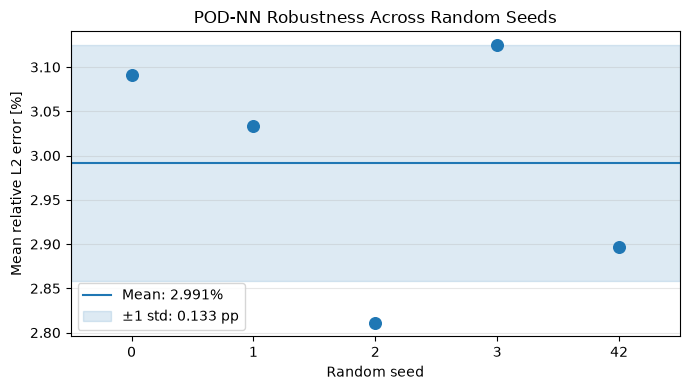

In [30]:

fig, ax = plt.subplots(figsize=(7, 4))

errors = seed_df["Mean L2 [%]"].to_numpy()
seed_ids = seed_df["Seed"].to_numpy()

# Equally spaced positions for categorical seed IDs
x = np.arange(len(seed_ids))

mean_error = errors.mean()
std_error = errors.std(ddof=1)

ax.scatter(x, errors, s=70, zorder=3)

ax.axhline(
    mean_error,
    color="tab:blue",
    linestyle="-",
    label=f"Mean: {mean_error:.3f}%"
)

ax.axhspan(
    mean_error - std_error,
    mean_error + std_error,
    color="tab:blue",
    alpha=0.15,
    label=f"±1 std: {std_error:.3f} pp"
)

ax.set_xlabel("Random seed")
ax.set_ylabel("Mean relative L2 error [%]")
ax.set_title("POD-NN Robustness Across Random Seeds")

ax.set_xticks(x)
ax.set_xticklabels(seed_ids)
ax.set_xlim(-0.5, len(seed_ids) - 0.5)

ax.grid(alpha=0.3, axis="y")
ax.legend()

plt.tight_layout()
plt.show()


### Robustness Assessment Across Random Seeds

To evaluate the robustness of the selected POD-NN architecture, we repeat the training with **five different random seeds**, keeping all hyperparameters unchanged.

The results show good consistency across runs:

- **Mean relative $L^2$ error:** $2.99 \pm 0.13\%$, ranging from $2.81\%$ to $3.12\%$.
- **Worst-trajectory error:** $4.50 \pm 0.37\%$, remaining below $5.2\%$ for all seeds.
- **Maximum snapshot error:** $37.34 \pm 0.81\%$, indicating that a few individual snapshots remain challenging despite the low overall errors.

The limited variability in validation performance suggests that the selected configuration is **robust to random initialization**, rather than relying on a particularly favorable seed.

Overall, the model achieves consistently low mean and worst-trajectory errors, supporting the reliability of the selected architecture.

Selecting

In [31]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

final_config = {
    "hidden_layers": (128,) * 5,
    "activation": "silu",
    "lr": 3e-3,
    "weight_decay": 0.0,
    "batch_size": 64,
    "max_epochs": 1500,
    "seed": 42,
}

# Use the checkpoint from the seed robustness experiment
final_result = seed_results[42]

assert Path(final_result["checkpoint_path"]).exists()
assert final_result["cached"] or Path(final_result["checkpoint_path"]).exists()

final_model = final_result["model"]
final_model.eval()

print("Final checkpoint:", final_result["checkpoint_path"])
print("Experiment ID:", final_result["experiment_id"])
print("Parameters:", final_result["parameters"])
print("Validation L2 [%]:",
      100 * final_result["metrics"]["mean_error"])


Final checkpoint: models/podnn_N50_W128_D5_silu_lr3e-03_wd0e+00_bs64_ep1500_s42_f5279a7293d34018.pt
Experiment ID: f5279a7293d34018
Parameters: 73138
Validation L2 [%]: 2.896192068742357


In [32]:

# POD-NN validation prediction
val_eval = sf.evaluate_model_L2(
    final_model, X_val_nn, u_val, Vn, M, scaler
)

u_val_nn = val_eval["prediction"]
err_nn = val_eval["errors"]             # (N_val, N_t)

# Best possible reconstruction within the selected POD space
A_val_projection = sf.project_l2(u_val, Vn, M)
u_val_pod = sf.reconstruct_pod(
    A_val_projection, Vn
)

err_pod = sf.relative_l2_error(
    u_val, u_val_pod, M
)

pod_summary = sf.summarize_errors(err_pod)

print(f"POD projection mean L2: {100 * pod_summary['mean_error']:.4f}%")
print(f"POD-NN mean L2:         {100 * val_eval['mean_error']:.4f}%")
print(f"POD-NN worst trajectory: {100 * val_eval['worst_trajectory_error']:.4f}%")
print(f"POD-NN max snapshot:     {100 * val_eval['max_snapshot_error']:.4f}%")


POD projection mean L2: 1.7704%
POD-NN mean L2:         2.8962%
POD-NN worst trajectory: 4.2978%
POD-NN max snapshot:     36.3347%



### Temporal Evolution and Decomposition of Validation Errors

The temporal evolution of the approximation error is analyzed to assess both the accuracy of the POD-NN model and the relative importance of its two error sources.

**Upper panel — Error magnitude and variability.**

For each time instant, the mean relative $L^2$ error is computed across all validation trajectories:

$$
\overline{e}(t_j)
=
\frac{1}{N_{\mathrm{val}}}
\sum_{k=1}^{N_{\mathrm{val}}}
e(\mu_k,t_j)
$$

The solid curves represent the mean POD projection and total POD-NN errors, while the shaded regions indicate their 10th–90th percentile ranges, describing the variability across parameter configurations. The dashed curve shows the mean NN regression error.

**Lower panel — Error source contributions.**

The relative contributions of POD projection and NN regression are evaluated from their squared relative errors, exploiting the orthogonal decomposition:

$$
e_{\mathrm{total}}^2(\mu,t)
=
e_{\mathrm{POD}}^2(\mu,t)
+
e_{\mathrm{reg}}^2(\mu,t)
$$

At each time instant, the percentage contribution of each component is computed as:

$$
s_{\mathrm{POD}}(t_j)
=
100
\frac{
\sum_k e_{\mathrm{POD}}^2(\mu_k,t_j)
}{
\sum_k e_{\mathrm{total}}^2(\mu_k,t_j)
}
$$

$$
s_{\mathrm{reg}}(t_j)=100-s_{\mathrm{POD}}(t_j)
$$

The stacked area chart illustrates how the balance between POD truncation and neural-network regression errors changes over time.

Together, the two panels distinguish the **magnitude and variability of the approximation error** from the **relative contribution of its two sources**.


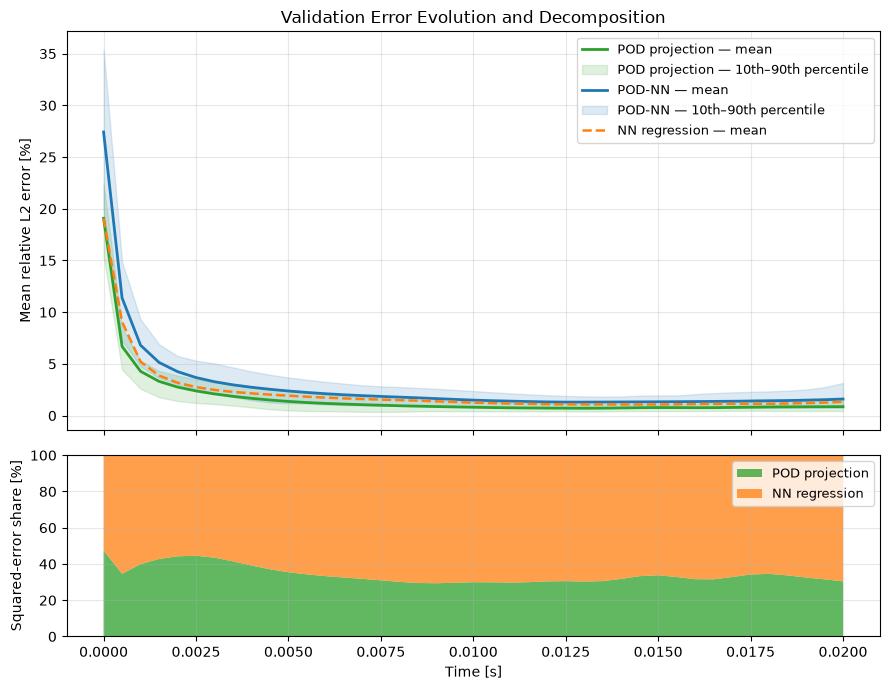

In [41]:

t = np.asarray(time_grid)

assert len(t) == u_val.shape[1], "Time grid length mismatch"

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(9, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1]}
)

# Snapshot-wise NN regression error, normalized by FOM norm
err_reg = (
    sf.l2_norm(u_val_pod - u_val_nn, M)
    / sf.l2_norm(u_val, M)
)
# ---------------------------------------------------
# 1. Temporal evolution of relative L2 errors
# ---------------------------------------------------

for errors, label, color in [
    (err_pod, "POD projection", "tab:green"),
    (err_nn, "POD-NN", "tab:blue"),
]:
    mean = 100 * np.nanmean(errors, axis=0)
    p10 = 100 * np.nanpercentile(errors, 10, axis=0)
    p90 = 100 * np.nanpercentile(errors, 90, axis=0)

    ax1.plot(
        t, mean,
        color=color, lw=2,
        label=f"{label} — mean"
    )

    ax1.fill_between(
        t, p10, p90,
        color=color, alpha=0.15,
        label=f"{label} — 10th–90th percentile"
    )

# NN regression error (mean only)
mean_reg = 100 * np.nanmean(err_reg, axis=0)

ax1.plot(
    t, mean_reg,
    color="tab:orange",
    lw=1.8,
    linestyle="--",
    label="NN regression — mean"
)

ax1.set_ylabel("Mean relative L2 error [%]")
ax1.set_title("Validation Error Evolution and Decomposition")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=9)

# ---------------------------------------------------
# 2. Contributions to total squared relative error
# ---------------------------------------------------

q_pod = np.mean(err_pod**2, axis=0)
q_reg = np.mean(err_reg**2, axis=0)
q_total = q_pod + q_reg

share_pod = np.divide(
    100 * q_pod,
    q_total,
    out=np.full_like(q_total, np.nan),
    where=q_total > 0
)

share_reg = np.divide(
    100 * q_reg,
    q_total,
    out=np.full_like(q_total, np.nan),
    where=q_total > 0
)

ax2.stackplot(
    t,
    share_pod,
    share_reg,
    colors=["tab:green", "tab:orange"],
    labels=["POD projection", "NN regression"],
    alpha=0.75
)

ax2.set_xlabel("Time [s]")
ax2.set_ylabel("Squared-error share [%]")
ax2.set_ylim(0, 100)
ax2.grid(alpha=0.3)
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()



### POD Projection and Neural Network Regression Errors

The total POD-NN approximation error can be decomposed into two orthogonal contributions:

1. **POD projection error:** the error introduced by approximating the FOM solution within the reduced POD space.
2. **NN regression error:** the additional error introduced by the neural network when predicting the reduced coefficients.

For each parameter configuration $\mu$ and time instant $t$, the relative errors are defined as:

$$
e_{\mathrm{POD}}(\mu,t)
=
\frac{\|u_h(\mu,t)-u_{\mathrm{POD}}(\mu,t)\|_M}
{\|u_h(\mu,t)\|_M}
$$

$$
e_{\mathrm{reg}}(\mu,t)
=
\frac{\|u_{\mathrm{POD}}(\mu,t)-u_{\mathrm{POD-NN}}(\mu,t)\|_M}
{\|u_h(\mu,t)\|_M}
$$

where $\|v\|_M=\sqrt{v^TMv}$ denotes the mass-matrix-induced $L^2$ norm.

Since the POD basis is $M$-orthonormal and the POD reconstruction is an orthogonal projection, the two contributions satisfy the Pythagorean identity:

$$
e_{\mathrm{total}}^2(\mu,t)
=
e_{\mathrm{POD}}^2(\mu,t)
+
e_{\mathrm{reg}}^2(\mu,t)
$$

To compare different validation trajectories, both error components are averaged over the $N_t$ time snapshots:

$$
\overline{e}_k
=
\frac{1}{N_t}
\sum_{j=1}^{N_t}e(\mu_k,t_j)
$$

Each point in the scatter plot represents one validation trajectory, with its time-averaged POD projection error on the horizontal axis and its time-averaged NN regression error on the vertical axis.

The **Pearson correlation coefficient** $r$ measures the linear association between the two error components across validation trajectories. A positive correlation would indicate that parameter configurations that are difficult to represent within the POD space also tend to be difficult for the neural network to approximate.

Finally, the contribution of NN regression to the total squared relative error is quantified as:

$$
\eta_{\mathrm{reg}}
=
\frac{\sum_{k,j} e_{\mathrm{reg}}^2(\mu_k,t_j)}
{\sum_{k,j} e_{\mathrm{total}}^2(\mu_k,t_j)}
\times 100\%
$$

This provides a quantitative measure of how much of the overall squared relative error originates from the neural-network approximation rather than from POD truncation.



Maximum decomposition residual: 8.539e-14
Correlation POD vs total:      0.909
Correlation POD vs regression: 0.796
NN contribution to squared relative error: 56.05%


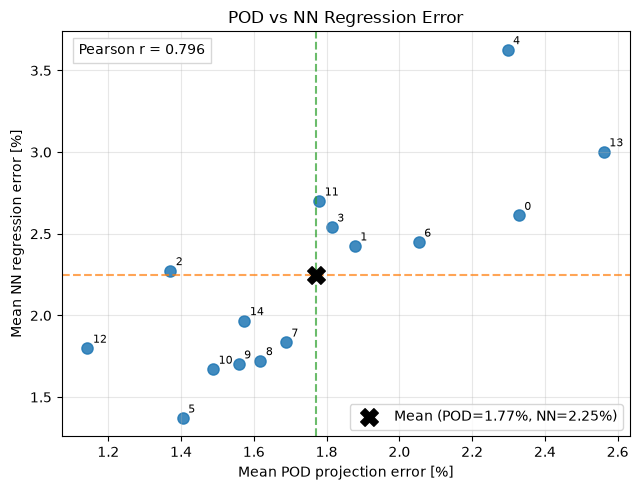

In [ ]:

from scipy.stats import pearsonr


# Time-averaged errors for each validation trajectory
traj_pod = 100 * np.mean(err_pod, axis=1)
traj_reg = 100 * np.mean(err_reg, axis=1)
traj_total = 100 * np.mean(err_nn, axis=1)

# Correlations across trajectories
r_pod_total = pearsonr(traj_pod, traj_total).statistic
r_pod_reg = pearsonr(traj_pod, traj_reg).statistic

# Exact decomposition check at snapshot level
residual = err_nn**2 - err_pod**2 - err_reg**2
print(f"Maximum decomposition residual: {np.max(np.abs(residual)):.3e}")

# Global squared-error contribution of regression
reg_fraction = (
    np.sum(err_reg**2) / np.sum(err_nn**2)
)

print(f"Correlation POD vs total:      {r_pod_total:.3f}")
print(f"Correlation POD vs regression: {r_pod_reg:.3f}")
print(f"NN contribution to squared relative error: {100*reg_fraction:.2f}%")

fig, ax = plt.subplots(figsize=(6.5, 5))

ax.scatter(
    traj_pod, traj_reg,
    s=65, color="tab:blue", alpha=0.85
)

for i, (xp, yp) in enumerate(zip(traj_pod, traj_reg)):
    ax.annotate(
        str(i), (xp, yp),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Mean POD projection error [%]")
ax.set_ylabel("Mean NN regression error [%]")

ax.set_title("POD vs NN Regression Error")

ax.text(
    0.03, 0.97,
    f"Pearson r = {r_pod_reg:.3f}",
    transform=ax.transAxes,
    ha="left", va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="lightgray",
        alpha=0.9
    )
)


ax.grid(alpha=0.3)
plt.tight_layout()

mean_traj_pod = traj_pod.mean()
mean_traj_reg = traj_reg.mean()

ax.axvline(
    mean_traj_pod,
    color="tab:green",
    linestyle="--",
    alpha=0.7
)

ax.axhline(
    mean_traj_reg,
    color="tab:orange",
    linestyle="--",
    alpha=0.7
)

ax.scatter(
    mean_traj_pod,
    mean_traj_reg,
    marker="X",
    s=160,
    color="black",
    zorder=5,
    label=(
        f"Mean (POD={mean_traj_pod:.2f}%, "
        f"NN={mean_traj_reg:.2f}%)"
    )
)

ax.legend()

plt.show()



### Comparison of Relative $L^2$ Error Metrics

Throughout model selection and hyperparameter tuning, the **Mean Relative $L^2$ Error** was adopted as the primary accuracy metric. It measures the average relative approximation error across validation trajectories and time snapshots, assigning equal weight to each snapshot:

$$
E_{\mathrm{mean}}
=
\frac{1}{N_{\mathrm{val}}N_t}
\sum_{k=1}^{N_{\mathrm{val}}}
\sum_{j=1}^{N_t}
e_{k,j}
$$

This choice provides an intuitive measure of typical prediction accuracy and ensures consistency across all hyperparameter comparisons.

However, a single metric cannot fully characterize the approximation quality. We therefore complement it with two additional measures:

**1. RMS Relative $L^2$ Error**

$$
E_{\mathrm{RMS}}
=
\sqrt{
\frac{1}{N_{\mathrm{val}}N_t}
\sum_{k=1}^{N_{\mathrm{val}}}
\sum_{j=1}^{N_t}
e_{k,j}^2
}
$$

By squaring individual relative errors before averaging, the RMS metric gives greater importance to snapshots with large errors. It is therefore useful for assessing the influence of particularly inaccurate predictions. Moreover, it preserves the orthogonal POD-NN error decomposition at the aggregate level:

$$
E_{\mathrm{total,RMS}}^2
=
E_{\mathrm{POD,RMS}}^2
+
E_{\mathrm{reg,RMS}}^2
$$

**2. Global Relative $L^2$ Error**

$$
E_{\mathrm{global}}
=
\sqrt{
\frac{
\sum_{k,j}
\|u_h(\mu_k,t_j)-\hat{u}(\mu_k,t_j)\|_M^2
}{
\sum_{k,j}
\|u_h(\mu_k,t_j)\|_M^2
}
}
$$

Unlike the previous metrics, which assign equal weight to each snapshot's relative error, the global metric weights errors according to the squared $L^2$ norm of the corresponding FOM solution.

This distinction is particularly relevant for time-dependent problems, where the solution magnitude may vary considerably during the evolution. Snapshots with very small solution norms can exhibit large relative errors despite having small absolute approximation errors.

**Comparison objective.**

The three metrics are evaluated on the same validation dataset for the POD projection, NN regression and complete POD-NN approximation. Their comparison provides complementary information:

- **Mean:** typical relative prediction accuracy.
- **RMS:** sensitivity to large relative errors.
- **Global:** approximation accuracy relative to the overall energy of the FOM solutions.

The Mean Relative $L^2$ Error remains the reference metric for model selection, while RMS and Global Relative $L^2$ Errors provide additional diagnostics without changing the previously established selection criterion.


In [45]:
# FOM snapshot norms (shape: N_val, N_t)
fom_norm = sf.l2_norm(u_val, M)

def error_metrics(relative_errors, reference_norms):
    relative_errors = np.asarray(relative_errors)
    reference_norms = np.asarray(reference_norms)

    assert relative_errors.shape == reference_norms.shape

    mean_error = np.mean(relative_errors)

    rms_error = np.sqrt(
        np.mean(relative_errors**2)
    )

    global_error = np.sqrt(
        np.sum((relative_errors * reference_norms)**2)
        / np.sum(reference_norms**2)
    )

    return {
        "Mean relative L2 [%]": 100 * mean_error,
        "RMS relative L2 [%]": 100 * rms_error,
        "Global relative L2 [%]": 100 * global_error,
    }


metric_comparison = pd.DataFrame({
    "POD projection": error_metrics(err_pod, fom_norm),
    "NN regression": error_metrics(err_reg, fom_norm),
    "Total POD-NN": error_metrics(err_nn, fom_norm),
}).T

print(metric_comparison.round(4).to_string())

# Consistency checks
assert np.isclose(
    metric_comparison.loc["Total POD-NN", "Mean relative L2 [%]"],
    100 * val_eval["mean_error"],
    rtol=1e-6,
    atol=1e-8,
)

for metric in ["RMS relative L2 [%]", "Global relative L2 [%]"]:
    lhs = metric_comparison.loc["Total POD-NN", metric]**2
    rhs = (
        metric_comparison.loc["POD projection", metric]**2
        + metric_comparison.loc["NN regression", metric]**2
    )

    print(f"{metric} — decomposition residual: {abs(lhs-rhs):.3e}")


                Mean relative L2 [%]  RMS relative L2 [%]  Global relative L2 [%]
POD projection                1.7704               3.5416                  1.7675
NN regression                 2.2465               3.9997                  2.1918
Total POD-NN                  2.8962               5.3423                  2.8157
RMS relative L2 [%] — decomposition residual: 4.214e-12
Global relative L2 [%] — decomposition residual: 1.942e-12



**Results interpretation.**

The POD-NN model achieves a **Mean Relative $L^2$ Error of 2.90%**, consistent with the metric used throughout model selection.

As expected from the previous temporal analysis, the RMS error is considerably higher (5.34%). This is mainly associated with the large relative errors observed during the initial time steps, where the rapidly evolving solution is more difficult to approximate accurately. Squaring the errors gives these poorly approximated snapshots greater influence on the RMS metric.

Conversely, the Global Relative $L^2$ Error (2.82%) remains close to the arithmetic mean, suggesting that the large initial relative errors have a limited impact when weighted by the magnitude of the FOM solution.

The NN regression error is larger than the POD projection error across all three metrics, indicating that neural-network approximation is the more significant source of error, although POD truncation remains relevant.

Finally, the negligible decomposition residuals (approximately $10^{-12}$) confirm the numerical consistency of the orthogonal error decomposition.


## Final POD-NN Evaluation on the Test Set

After completing hyperparameter tuning and model selection using the validation set, the final POD-NN surrogate is evaluated on the previously unseen test trajectories.

The neural network weights, POD basis (50 modes), coefficient scaling parameters, and all hyperparameters are kept fixed. No further training, optimization, or model selection is performed using test data.

The evaluation follows the same procedure adopted during validation, using the finite element mass matrix to compute spatial  $L^2$ errors.

The primary performance metric is the **Mean Relative $L^2$ Error**, averaged over time and then across test trajectories, as specified in the assignment. Additional metrics, including RMS and Global Relative  $L^2$ Errors, are reported to provide a more comprehensive assessment of generalization.

The POD projection error is also evaluated on the test set to distinguish the intrinsic approximation limitations of the reduced basis from the additional error introduced by neural network regression.

In [ ]:
# ============================================================
# FINAL TEST EVALUATION — FROZEN POD-NN
# ============================================================

# Freeze the selected model
final_model.eval()
final_model.requires_grad_(False)

# Prepare test inputs using the existing preprocessing
X_test_nn = sf.make_nn_inputs(mu_test, time_grid)

# POD-NN predictions and relative L2 errors
test_eval = sf.evaluate_model_L2(
    final_model, X_test_nn, u_test, Vn, M, scaler
)

u_test_nn = test_eval["prediction"]
err_nn_test = test_eval["errors"]

# Exact POD projection onto the frozen training basis
A_test = sf.project_l2(u_test, Vn, M)
u_test_pod = sf.reconstruct_pod(A_test, Vn)

err_pod_test = sf.relative_l2_error(
    u_test, u_test_pod, M
)

# Same metric definitions used during validation
fom_norm_test = sf.l2_norm(u_test, M)

nn_metrics_test = error_metrics(
    err_nn_test, fom_norm_test
)
pod_metrics_test = error_metrics(
    err_pod_test, fom_norm_test
)

print("FINAL TEST RESULTS")
print("-" * 45)

print(f"Mean relative L2:   {nn_metrics_test['Mean relative L2 [%]']:.4f}%")
print(f"RMS relative L2:    {nn_metrics_test['RMS relative L2 [%]']:.4f}%")
print(f"Global relative L2: {nn_metrics_test['Global relative L2 [%]']:.4f}%")

print(f"POD projection mean: {100 * np.mean(err_pod_test):.4f}%")

print(f"Median trajectory error: {100 * test_eval['median_error']:.4f}%")
print(f"Worst trajectory error:  {100 * test_eval['worst_trajectory_error']:.4f}%")
print(f"Maximum snapshot error:  {100 * test_eval['max_snapshot_error']:.4f}%")

print("-" * 45)

criterion_passed = test_eval["mean_error"] < 0.10
print(f"Assignment accuracy criterion: {'PASS' if criterion_passed else 'FAIL'}")

FINAL TEST RESULTS
---------------------------------------------
Mean relative L2:   3.2480%
RMS relative L2:    6.4179%
Global relative L2: 3.2919%
POD projection mean: 1.7792%
Median trajectory error: 3.2272%
Worst trajectory error:  6.3768%
Maximum snapshot error:  50.5533%
---------------------------------------------
Assignment accuracy criterion: PASS


### Final Test Results

The POD-NN model achieves a **mean relative L2 error of 3.25%** on the unseen test set, successfully satisfying the assignment's 10% accuracy threshold. The results are consistent with validation performance, suggesting good generalization without significant overfitting.

The POD projection error (1.78%) provides a lower bound on the reconstruction error achievable with the selected basis. The higher POD-NN error reflects the additional approximation introduced by the neural network.

Although the maximum snapshot error reaches 50.55%, the worst trajectory-averaged error remains limited to 6.38%, indicating that large errors are concentrated in individual snapshots rather than entire trajectories.

### Generalization Assessment: Validation vs Test

The generalization performance of the final POD-NN model is assessed by comparing its prediction errors on the validation and test datasets, without further modifying the trained network or the POD basis.

Three complementary analyses are considered:

1. **Error metrics comparison:** mean, RMS and global relative $L^2$ errors are compared, together with the POD projection error. The differences $\Delta E = E_{\mathrm{test}} - E_{\mathrm{val}}$ are reported in percentage points to quantify the generalization gap.
2. **POD and NN error decomposition:** the mean POD projection error is plotted against the mean NN regression error for each trajectory, comparing validation and test samples. This allows us to investigate the relationship between the two error sources, identify challenging parameter configurations, and assess whether the generalization gap is mainly associated with the reduced basis or the neural network.
3. **Temporal error evolution:** the mean relative $L^2$ error across trajectories is plotted as a function of time, highlighting the time intervals where the model is less accurate.

These analyses provide a more complete assessment of predictive accuracy, robustness and generalization to unseen parameter configurations.

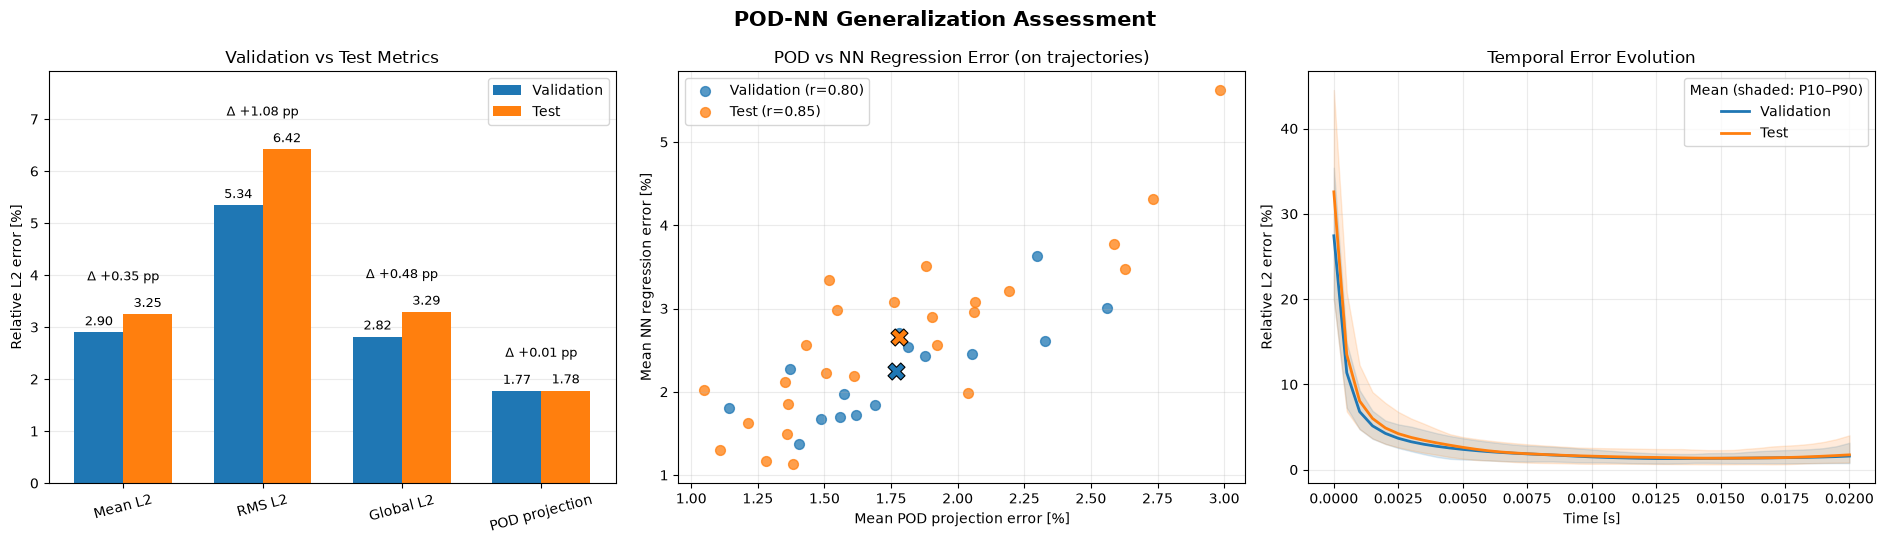

In [ ]:
# -------------------------------------------------------
# Data preparation
# -------------------------------------------------------
t = np.asarray(time_grid)

assert err_nn.shape[1] == len(t)
assert err_nn_test.shape[1] == len(t)

val_norms = sf.l2_norm(u_val, M)
test_norms = sf.l2_norm(u_test, M)

val_metrics = error_metrics(err_nn, val_norms)
test_metrics = error_metrics(err_nn_test, test_norms)

metric_names = [
    "Mean relative L2 [%]",
    "RMS relative L2 [%]",
    "Global relative L2 [%]",
]

validation = np.array(
    [val_metrics[name] for name in metric_names]
    + [100 * np.mean(err_pod)]
)

test = np.array(
    [test_metrics[name] for name in metric_names]
    + [100 * np.mean(err_pod_test)]
)

labels = [
    "Mean L2", "RMS L2",
    "Global L2", "POD projection"
]

# -------------------------------------------------------
# Summary figure
# -------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# 1. Validation vs test metrics
ax = axes[0]
x = np.arange(len(labels))
width = 0.35

bars_val = ax.bar(
    x - width / 2, validation, width,
    label="Validation", color="tab:blue"
)
bars_test = ax.bar(
    x + width / 2, test, width,
    label="Test", color="tab:orange"
)

ax.bar_label(bars_val, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(bars_test, fmt="%.2f", padding=3, fontsize=9)

# Generalization gap in percentage points
for i, (v, te) in enumerate(zip(validation, test)):
    delta = te - v
    ax.text(
        x[i], max(v, te) + 0.65,
        f"Δ {delta:+.2f} pp",
        ha="center", fontsize=9
    )

ax.set_xticks(x, labels, rotation=15)
ax.set_ylabel("Relative L2 error [%]")
ax.set_title("Validation vs Test Metrics")
ax.set_ylim(0, max(validation.max(), test.max()) + 1.5)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# 2. POD projection vs NN regression error
ax = axes[1]

# Regression error relative to the FOM norm
err_reg_test = (
    sf.l2_norm(u_test_pod - u_test_nn, M)
    / sf.l2_norm(u_test, M)
)

datasets = [
    ("Validation", err_pod, err_reg, "tab:blue"),
    ("Test", err_pod_test, err_reg_test, "tab:orange"),
]

for label, pod_error, reg_error, color in datasets:
    traj_pod = 100 * np.mean(pod_error, axis=1)
    traj_reg = 100 * np.mean(reg_error, axis=1)

    r = np.corrcoef(traj_pod, traj_reg)[0, 1]

    ax.scatter(
        traj_pod, traj_reg,
        s=50, alpha=0.75, color=color,
        label=f"{label} (r={r:.2f})"
    )

    ax.scatter(
        traj_pod.mean(), traj_reg.mean(),
        marker="X", s=150, color=color,
        edgecolor="black", linewidth=0.8,
        zorder=5
    )

ax.set_xlabel("Mean POD projection error [%]")
ax.set_ylabel("Mean NN regression error [%]")
ax.set_title("POD vs NN Regression Error (on trajectories)")
ax.legend()
ax.grid(alpha=0.25)

# 3. Temporal evolution of mean errors
ax = axes[2]

for errors, label, color in [
    (err_nn, "Validation", "tab:blue"),
    (err_nn_test, "Test", "tab:orange"),
]:
    mean = 100 * np.mean(errors, axis=0)
    p10 = 100 * np.percentile(errors, 10, axis=0)
    p90 = 100 * np.percentile(errors, 90, axis=0)

    ax.plot(t, mean, color=color, lw=2, label=label)
    ax.fill_between(t, p10, p90, color=color, alpha=0.15)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Relative L2 error [%]")
ax.set_title("Temporal Error Evolution")
ax.legend(title="Mean (shaded: P10–P90)")
ax.grid(alpha=0.25)

fig.suptitle(
    "POD-NN Generalization Assessment",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.show()

### Spatiotemporal Visualization of Test Predictions

To qualitatively assess the reconstruction accuracy of the final POD-NN model, three representative trajectories from the test dataset are selected according to their time-averaged relative $L^2$ errors: the best-performing trajectory, the trajectory closest to the mean error, and the worst-performing trajectory.

For each trajectory, the full-order solution (FOM), the POD-NN reconstruction, and the pointwise absolute error $|u_{\mathrm{FOM}}-u_{\mathrm{POD-NN}}|$ are visualized over time. Identical color limits are used for the FOM and POD-NN fields to ensure a consistent comparison.

In [ ]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Select trajectories using their time-averaged relative L2 errors
trajectory_errors = np.mean(err_nn_test, axis=1)

indices = {
    "Best": int(np.argmin(trajectory_errors)),
    "Representative": int(np.argmin(
        np.abs(trajectory_errors - trajectory_errors.mean())
    )),
    "Worst": int(np.argmax(trajectory_errors)),
}

selected = list(indices.items())

# Shared field scale across all selected trajectories and times
selected_ids = list(indices.values())
fom = u_test[selected_ids]
pred = u_test_nn[selected_ids]
abs_error = np.abs(fom - pred)

field_min = float(min(fom.min(), pred.min()))
field_max = float(max(fom.max(), pred.max()))

# Independent error scale; 99th percentile enhances contrast
error_max = float(np.percentile(abs_error, 99))
error_max = max(error_max, 1e-12)

field_norm = Normalize(vmin=field_min, vmax=field_max)
error_norm = Normalize(vmin=0, vmax=error_max)

field_cmap = sf.modify_jet_to_gray()
error_cmap = "inferno"

def draw_frame(j):
    fig, axes = plt.subplots(3, 3, figsize=(11, 7))

    for row, (label, idx) in enumerate(selected):
        fields = [
            u_test[idx, j],
            u_test_nn[idx, j],
            np.abs(u_test[idx, j] - u_test_nn[idx, j]),
        ]

        for col, field in enumerate(fields):
            ax = axes[row, col]
            plt.sca(ax)

            if col < 2:
                fe.plot(
                    field, Vh,
                    vmin=field_min, vmax=field_max,
                    cmap=field_cmap
                )
            else:
                fe.plot(
                    field, Vh,
                    vmin=0, vmax=error_max,
                    cmap=error_cmap
                )

            if row == 0:
                ax.set_title(
                    ["FOM", "POD-NN", "Absolute error"][col],
                    fontsize=11
                )

            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])

        # Row label, positioned outside the plots
        axes[row, 0].text(
            -0.12, 0.5,
            f"{label}\n"
            f"Trajectory {idx}\n"
            f"L2 = {100 * trajectory_errors[idx]:.2f}%",
            transform=axes[row, 0].transAxes,
            ha="right", va="center",
            fontsize=9, fontweight="bold"
        )

    fig.suptitle(
        f"Test Set Reconstruction — t = {time_grid[j]:.4f} s",
        fontsize=12, y=0.97
    )

    fig.subplots_adjust(
        left=0.19,
        right=0.87,
        bottom=0.06,
        top=0.90,
        wspace=0.04,
        hspace=0.12
    )

    # Shared colorbars
    cax_field = fig.add_axes([0.89, 0.54, 0.012, 0.27])
    cax_error = fig.add_axes([0.89, 0.17, 0.012, 0.27])

    fig.colorbar(
        ScalarMappable(norm=field_norm, cmap=field_cmap),
        cax=cax_field, label="Field value"
    )

    fig.colorbar(
        ScalarMappable(norm=error_norm, cmap=error_cmap),
        cax=cax_error, label="Absolute error"
    )

    return fig

# Save synchronized animation
gif_name = "test_reconstruction_3x3.gif"

def save_frame(j):
    fig = draw_frame(j)
    plt.close(fig)

    # The GIF writer captures the current figure
    plt.figure(fig.number)

gifs.save(draw_frame, len(time_grid), gif_name)

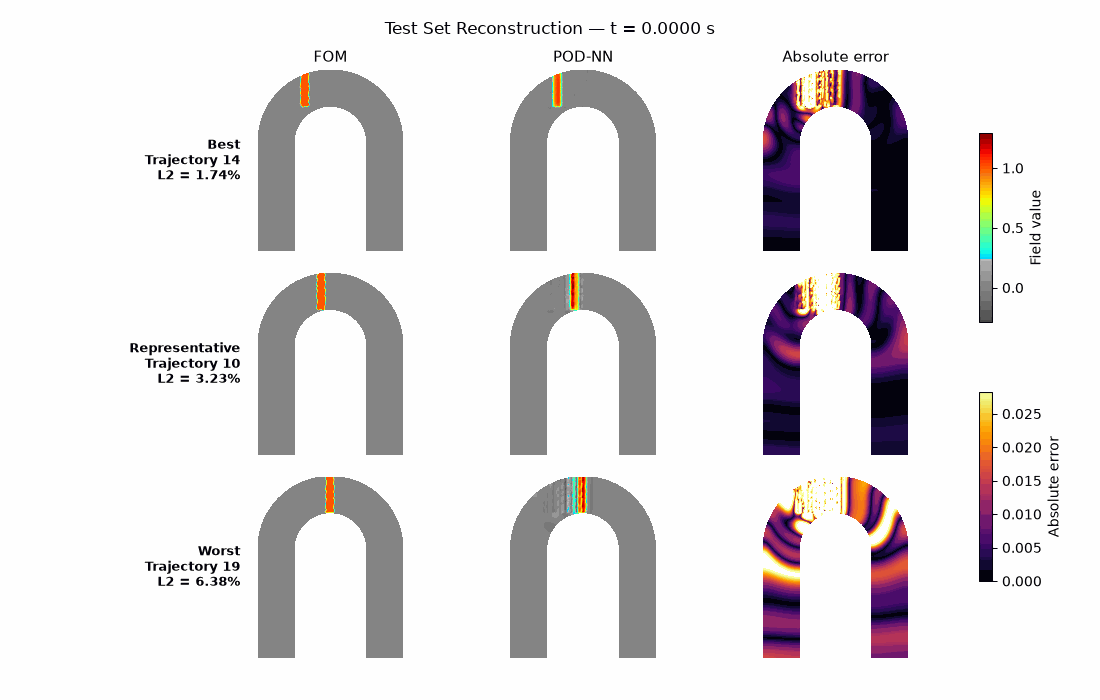

In [ ]:
display(Image(filename=gif_name, width=900))

### Computational Efficiency and Break-Even Analysis

The computational efficiency of the final POD-NN model is evaluated by comparing its offline training cost and online prediction time against the full-order model (FOM).

The **offline cost** is estimated as the average measured training time across the random seeds used in the robustness assessment, excluding cached runs. The **online cost** is measured by repeatedly evaluating the trained POD-NN over a complete test trajectory, including neural network inference, coefficient denormalization, and full-field reconstruction.

The resulting speedup is defined as

$$
S = \frac{t_{\mathrm{FOM}}}{t_{\mathrm{ROM}}}.
$$

Since the ROM requires an initial training investment, its total computational cost after $N$ trajectory evaluations is

$$
T_{\mathrm{ROM}}(N) = T_{\mathrm{offline}} + Nt_{\mathrm{ROM}},
$$

whereas the corresponding FOM cost is

$$
T_{\mathrm{FOM}}(N) = Nt_{\mathrm{FOM}}.
$$

The break-even point is therefore

$$
N_{\mathrm{BE}} =
\frac{T_{\mathrm{offline}}}{t_{\mathrm{FOM}}-t_{\mathrm{ROM}}},
$$

representing the number of complete trajectory evaluations required to compensate for the offline training cost.

In [ ]:
# -------------------------------------------------------
# Offline cost: mean training time across measured seeds
# -------------------------------------------------------
measured_times = seed_df["Training time [s]"].dropna()

if measured_times.empty:
    raise ValueError("No measured training times available.")

T_offline = measured_times.mean()
T_offline_std = measured_times.std(ddof=1)

print("OFFLINE COST")
print(f"Measured seeds:       {len(measured_times)}")
print(f"Mean training time:   {T_offline / 60:.2f} min")
print(f"Training time std:    {T_offline_std / 60:.2f} min")

# -------------------------------------------------------
# Online cost: complete test trajectory
# -------------------------------------------------------
fom_time = 19.33  # seconds per complete FOM trajectory

trajectory_errors = np.mean(err_nn_test, axis=1)
representative_idx = int(
    np.argmin(np.abs(trajectory_errors - trajectory_errors.mean()))
)

N_t = len(time_grid)

start = representative_idx * N_t
end = start + N_t

X_traj = X_test_nn[start:end]

benchmark = sf.benchmark_rom(
    final_model,
    X_traj,
    scaler,
    Vn,
    n_repeats=500,
    warmup=30,
    fom_time=fom_time,
)

t_rom = benchmark["mean"]
speedup = benchmark["speedup"]

# -------------------------------------------------------
# Break-even analysis
# -------------------------------------------------------
if t_rom >= fom_time:
    raise ValueError("ROM is not faster than FOM: no break-even.")

N_break_even = T_offline / (fom_time - t_rom)
N_break_even_integer = int(np.floor(N_break_even) + 1)

print("\nONLINE COST")
print(f"Test trajectory:      {representative_idx}")
print(f"FOM time:             {fom_time:.3f} s")
print(f"ROM mean time:        {t_rom * 1000:.3f} ms")
print(f"ROM median time:      {benchmark['median'] * 1000:.3f} ms")
print(f"ROM std:              {benchmark['std'] * 1000:.3f} ms")
print(f"Online speedup:       {speedup:,.1f}x")

print("\nBREAK-EVEN")
print(f"Theoretical:          {N_break_even:.2f} trajectories")
print(f"First profitable run: {N_break_even_integer} trajectories")

OFFLINE COST
Measured seeds:       4
Mean training time:   2.67 min
Training time std:    0.33 min

ONLINE COST
Test trajectory:      10
FOM time:             19.330 s
ROM mean time:        12.813 ms
ROM median time:      11.412 ms
ROM std:              5.169 ms
Online speedup:       1,508.7x

BREAK-EVEN
Theoretical:          8.28 trajectories
First profitable run: 9 trajectories


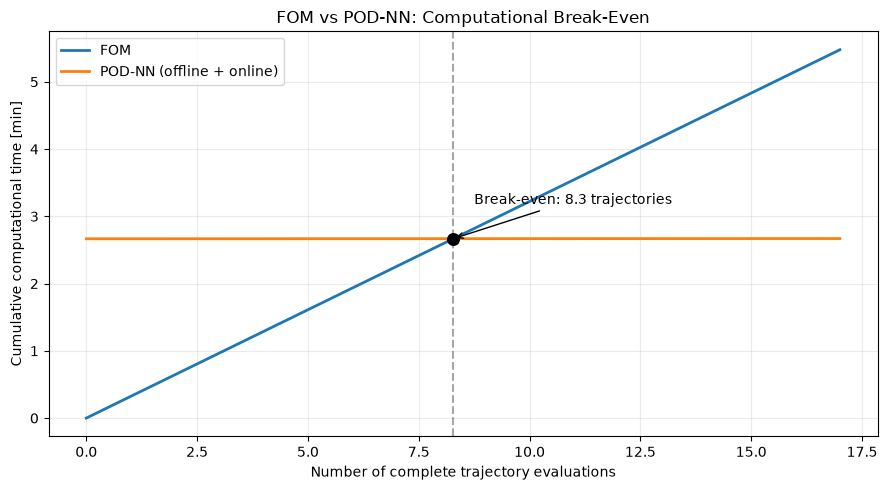

In [ ]:
# Show a range extending beyond the break-even point
N_max = max(10, int(np.ceil(2 * N_break_even)))
N = np.linspace(0, N_max, 500)

T_fom = N * fom_time / 60
T_rom = (T_offline + N * t_rom) / 60

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    N, T_fom,
    label="FOM", color="tab:blue", lw=2
)

ax.plot(
    N, T_rom,
    label="POD-NN (offline + online)",
    color="tab:orange", lw=2
)

# Break-even intersection
T_be = N_break_even * fom_time / 60

ax.scatter(
    N_break_even, T_be,
    color="black", s=70, zorder=5
)

ax.axvline(
    N_break_even,
    color="gray", linestyle="--", alpha=0.7
)

ax.annotate(
    f"Break-even: {N_break_even:.1f} trajectories",
    xy=(N_break_even, T_be),
    xytext=(15, 25),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10
)

ax.set_xlabel("Number of complete trajectory evaluations")
ax.set_ylabel("Cumulative computational time [min]")
ax.set_title("FOM vs POD-NN: Computational Break-Even")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
from IPython.display import display

display(fig)
plt.close(fig)

### Computational Performance: Results and Discussion

The final POD-NN model achieves an average online evaluation time of **12.81 ms per complete trajectory**, compared with the reference FOM time of **19.33 s**, corresponding to an online speedup of approximately **1,509×**.

The average training time across four measured random seeds is **2.67 ± 0.33 minutes**. Considering only this training cost, the break-even point is reached after approximately **8.28 trajectory evaluations**, meaning that the POD-NN becomes computationally advantageous from the **9th evaluation** onward.

However, this estimate represents a simplified break-even analysis. It excludes the computational cost of generating the FOM snapshots, constructing the POD basis, and performing hyperparameter tuning and model selection. Furthermore, the neural network was trained on a CPU, and the reported training time therefore depends on the available hardware and computational environment. The ROM benchmark and the reference FOM execution time may also have been obtained under different hardware conditions.

Consequently, the reported break-even point should be interpreted as a **training-only estimate**, rather than the total cost of developing the reduced-order model.

### Break-Even Sensitivity to Offline Costs

To investigate the influence of offline computational expenses, three scenarios are compared: the measured training-only cost, a hypothetical one-hour training and hyperparameter tuning budget, and the same budget augmented by the generation of 100 FOM trajectories.

The analysis assumes a constant online evaluation time and a reference FOM cost of 19.33 seconds per trajectory. The additional scenarios are illustrative estimates rather than directly measured computational costs.

The results highlight how the initial investment affects the number of subsequent evaluations required to recover the ROM development cost, while the substantial online speedup remains unchanged.

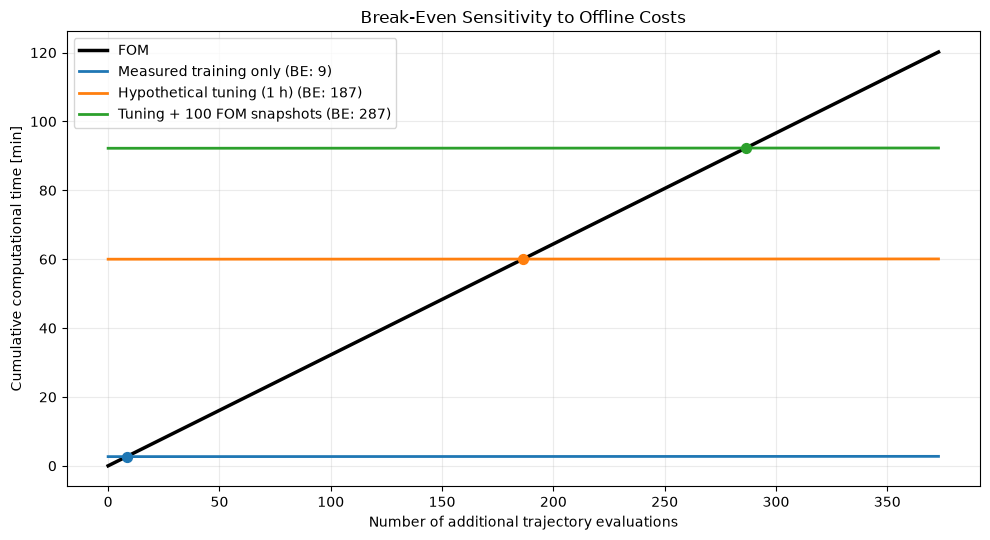

In [ ]:
# Offline scenarios (seconds)
offline_scenarios = {
    "Measured training only": T_offline,
    "Hypothetical tuning (1 h)": 3600,
    "Tuning + 100 FOM snapshots": 3600 + 100 * fom_time,
}

# Break-even points
break_even = {
    name: cost / (fom_time - t_rom)
    for name, cost in offline_scenarios.items()
}

N_max = int(np.ceil(max(break_even.values()) * 1.3))
N = np.linspace(0, N_max, 600)

fig, ax = plt.subplots(figsize=(10, 5.5))

# FOM baseline
ax.plot(
    N, N * fom_time / 60,
    color="black", lw=2.5,
    label="FOM"
)

colors = ["tab:blue", "tab:orange", "tab:green"]

for (name, cost), color in zip(offline_scenarios.items(), colors):
    total_time = (cost + N * t_rom) / 60
    n_be = break_even[name]

    ax.plot(
        N, total_time,
        color=color, lw=2,
        label=f"{name} (BE: {np.floor(n_be) + 1:.0f})"
    )

    ax.scatter(
        n_be, n_be * fom_time / 60,
        color=color, s=50, zorder=5
    )

ax.set_xlabel("Number of additional trajectory evaluations")
ax.set_ylabel("Cumulative computational time [min]")
ax.set_title("Break-Even Sensitivity to Offline Costs")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Practical Considerations on ROM Development

Beyond computational costs, the practical deployment of a POD-NN model also requires a non-negligible engineering effort. This includes implementing the reduced-order modelling pipeline, selecting and tuning the neural network architecture, debugging, validating the predictions, and assessing the model's reliability.

Such development effort is not captured by the computational break-even analysis and should be distinguished from CPU execution time. Although it represents an additional initial investment, it can be amortized when the trained ROM is reused for a sufficiently large number of simulations.

A comprehensive economic assessment would therefore require accounting for both engineering labour and computational resources. In this assignment, the break-even analysis is limited to computational time, while development effort is acknowledged as an additional practical consideration.